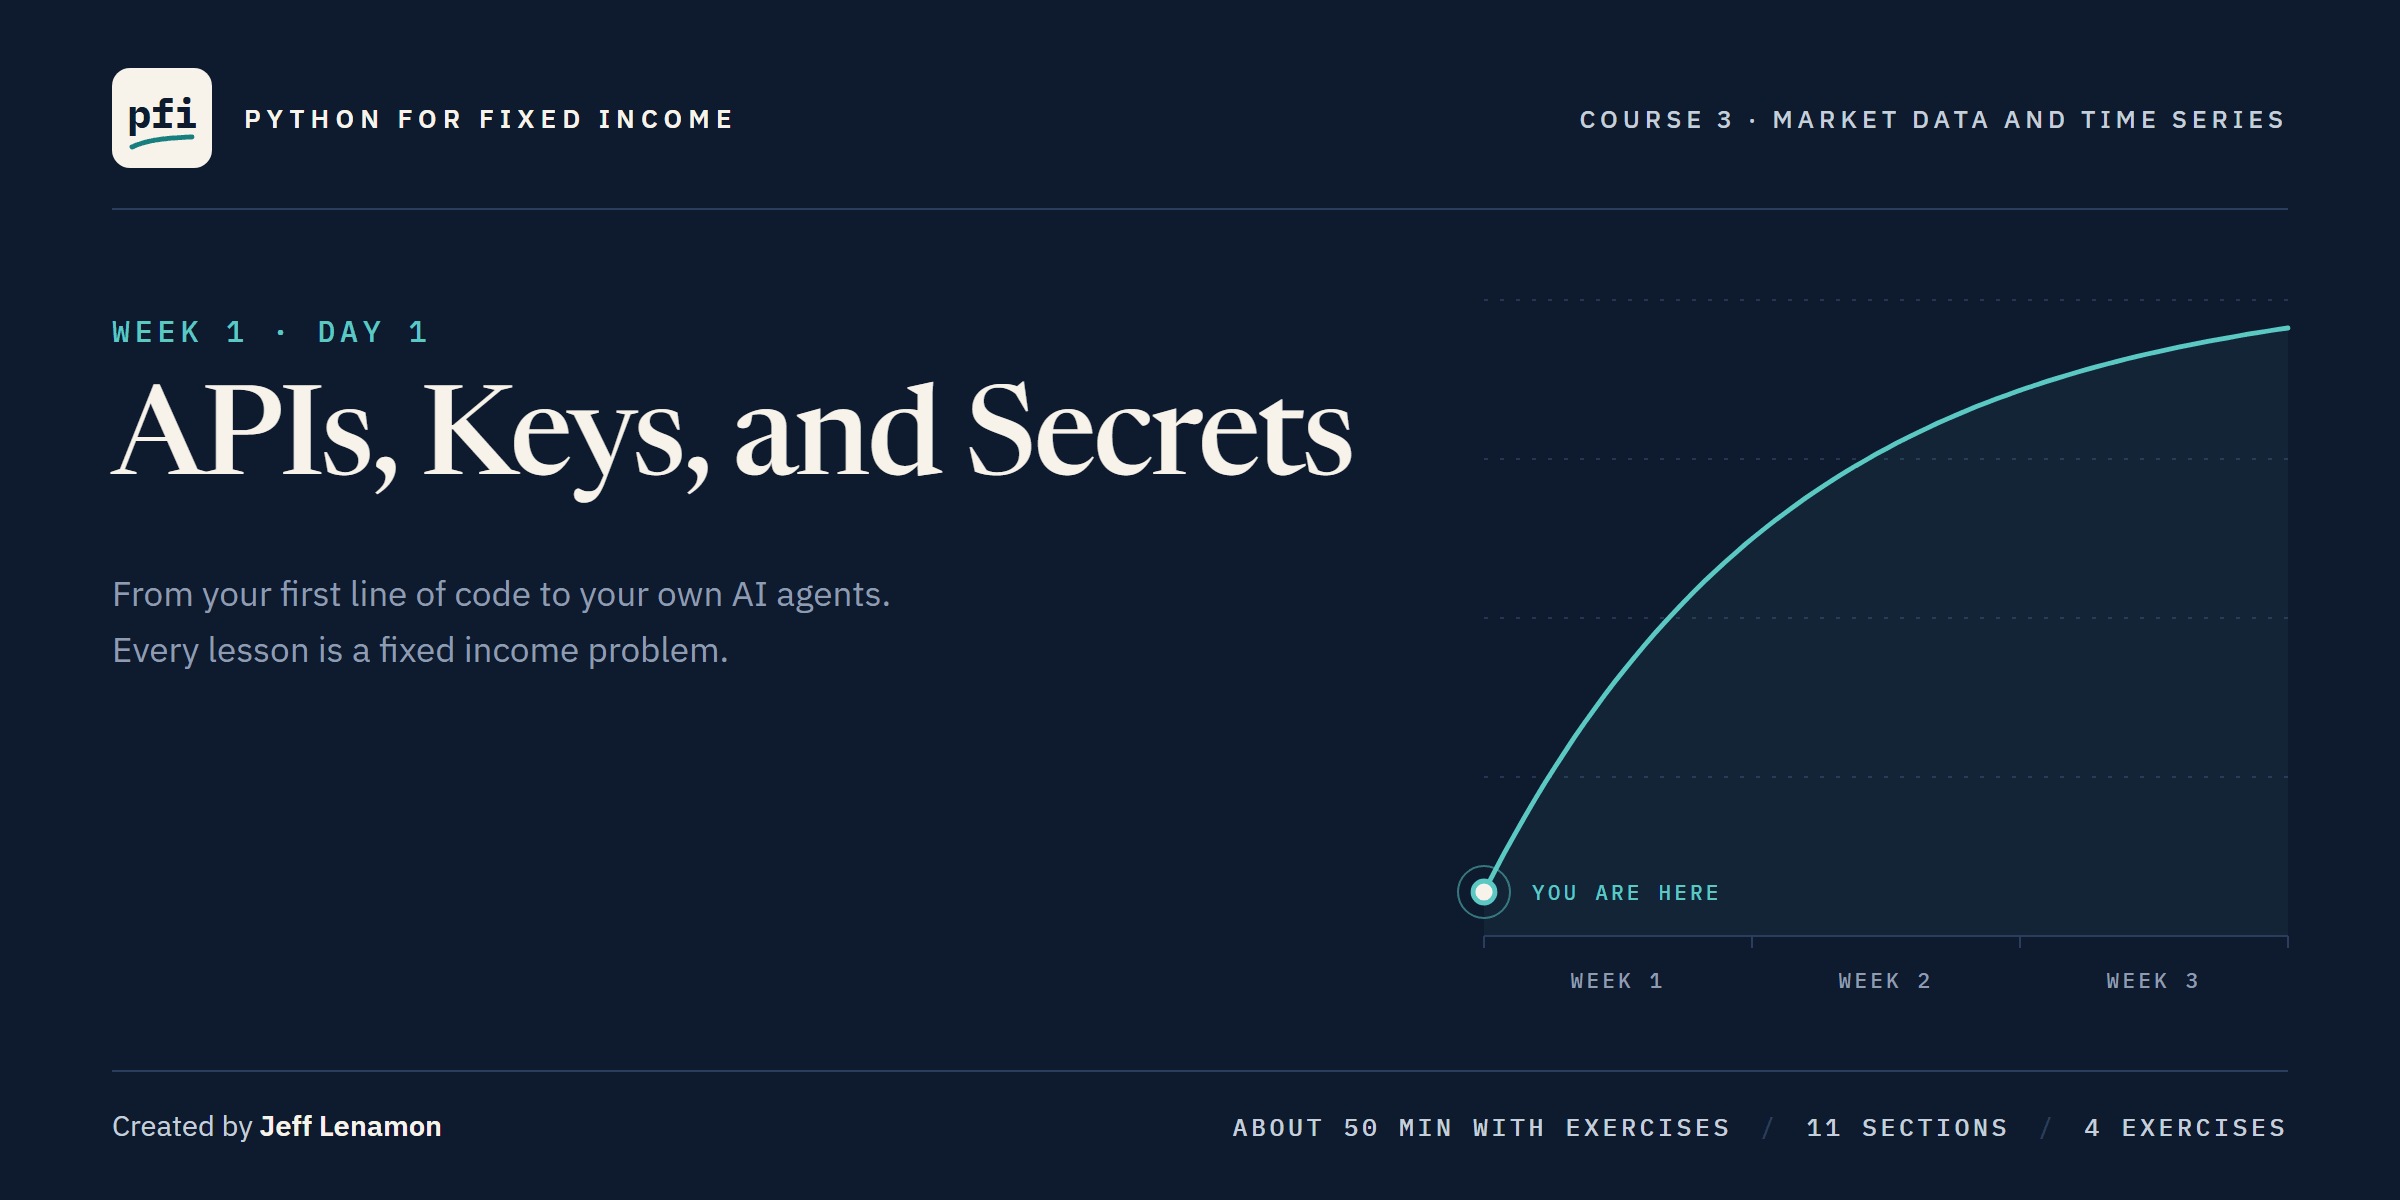

# APIs, Keys, and Secrets

Week 1, Day 1. What FRED sends back, a key kept outside the code, `get_secret` tested, and a first live pull tied to the Treasury file.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course03_market_data/week1/day1/01_apis_keys_and_secrets.ipynb)

### Welcome to Course 3

Course 2 ended with a bond math module of your own, tested against Excel.
Course 3 brings the market's own numbers in from outside, the same way: one tested function a day, in a new module.

### The Desk Lead's Note

> From today the morning numbers come from FRED, pulled by code. FRED wants a key on every request, in your name. Before any code touches a real key, show me what FRED sends back, checked against the Treasury file we trust. Get your own key and give it a home outside every file, notebook, and commit. Write the one function that finds it, tested. Pull the 10-year live and tie it to the snapshot. Then show me a key leaking, and the fix.

FRED is the Federal Reserve Bank of St. Louis's free data service.
Every cell runs without a key, the saved outputs are that run, and every demo uses a fake key.

**Every request carries a key in your name: today it gets a home outside the code before any code needs it.**

## Your Route Through Day 1

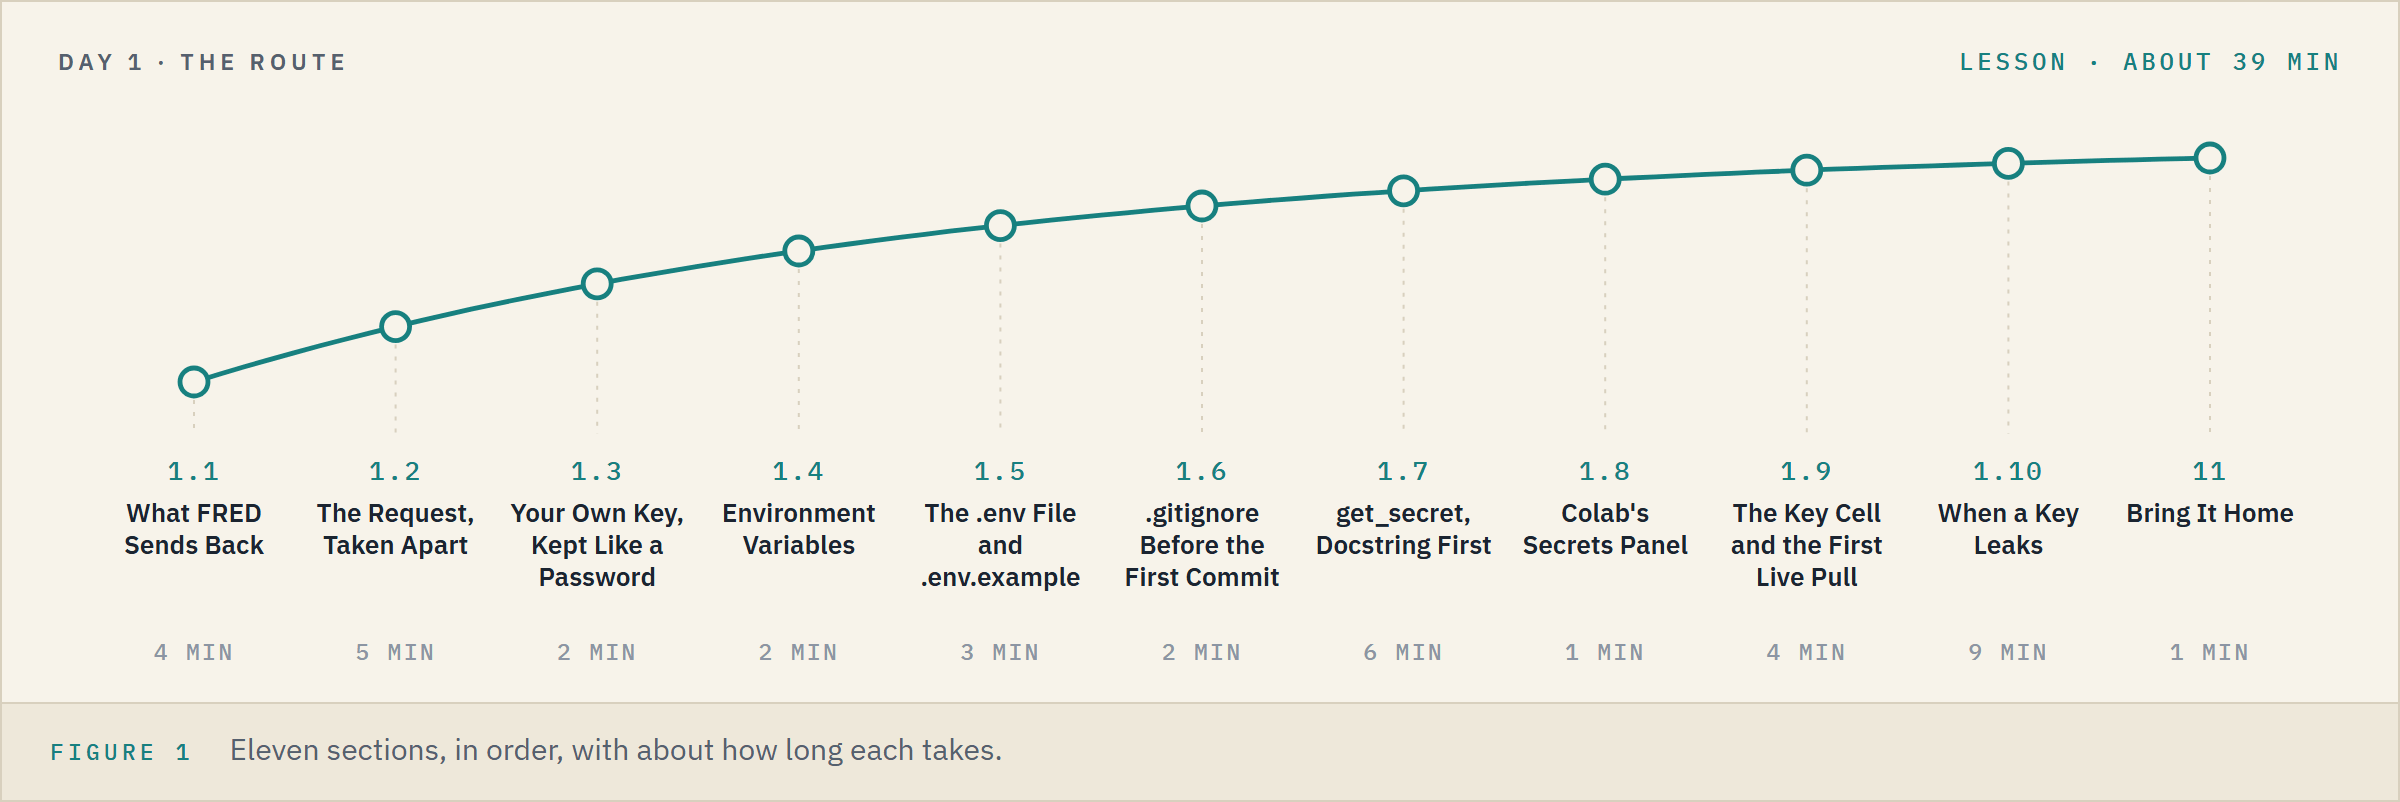

**Time.** About 39 minutes for the lesson, then about 12 for the four exercises.

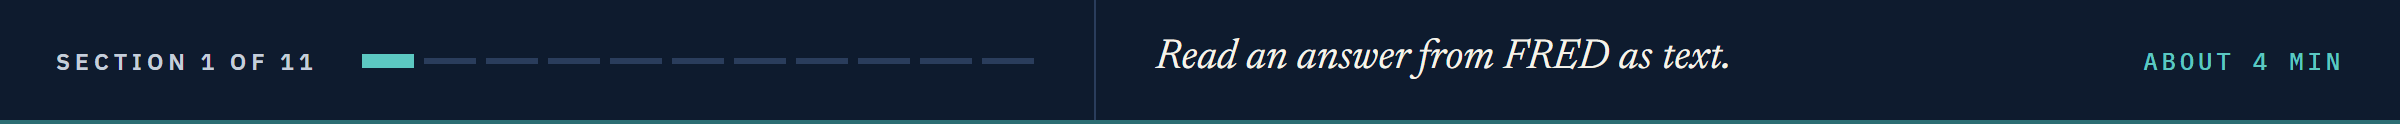

## 1.1 What FRED Sends Back

The note's first ask: before any key, see an answer.

### Start the Day

Q. Where does today's work happen?

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}course03_market_data/start_of_day/start_day.py
from start_day import start_day

# a new work folder: the data files, Course 2's bondmath.py, and an empty Git repository.
# To start the day again, restart the kernel and run all cells.
work = start_day(1)

Work folder pfi_course3_01_k4w7q2xr: 3 data files, Course 2's bondmath.py, no marketdata.py yet, a Git repository with no commits


`start_day(1)` copied in the Treasury file and an answer in FRED's format; `marketdata.py` starts today.

### Imports and the House Colours

In [2]:
import importlib
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import requests  # for the live pull in 1.9; importing it opens no connection
import seaborn as sns

# the house greens and greys, as in Course 1's Visualization notebook
sns.set_theme(style='whitegrid', palette=['#2E7D5B', '#9AA5B1', '#1E4D3A', '#52606D'])

### An Answer, Read as Text

Q. What does an answer from FRED look like?

In [3]:
# an answer in FRED's exact format, saved as a file: its lines, as in Course 1's Files and Folders
with open('course3_fred_format_dgs10.json', encoding='utf-8') as file:
    sample_lines = file.readlines()
# the first 19 lines, then the last 6: the last observation and the closing brackets
print(''.join(sample_lines[:19]) + '...\n' + ''.join(sample_lines[-6:]))

{
  "realtime_start": "2026-10-02",
  "realtime_end": "2026-10-02",
  "observation_start": "2026-08-03",
  "observation_end": "2026-09-30",
  "units": "lin",
  "output_type": 1,
  "file_type": "json",
  "order_by": "observation_date",
  "sort_order": "asc",
  "count": 43,
  "offset": 0,
  "limit": 100000,
  "observations": [
    {
      "realtime_start": "2026-10-02",
      "realtime_end": "2026-10-02",
      "date": "2026-08-03",
      "value": "4.70"
...
      "realtime_end": "2026-10-02",
      "date": "2026-09-30",
      "value": "5.29"
    }
  ]
}



The course built this file from Treasury's values in FRED's exact layout: 43 dated observations, from 4.70 on 3 August 2026 to 5.29 on 30 September.

### The Same Day in the Snapshot

Q. Does the Treasury file hold 5.29 on 30 September?

In [4]:
# the Treasury file, dates as the index; round_trip reads each number exactly as written
treasury = pd.read_csv('treasury_par_yields.csv', parse_dates=['date'], index_col='date',
                       float_precision='round_trip')
print(f'{len(treasury):,} market days, {treasury.index[0].date()} to {treasury.index[-1].date()}')
print('10 Yr on 2026-09-30:', treasury.loc['2026-09-30', '10 Yr'], 'percent')

2,940 market days, 2015-01-02 to 2026-10-02
10 Yr on 2026-09-30: 5.29 percent


This is the course's **snapshot**: the U.S. Treasury's par yield curve, public domain, frozen on 2 October 2026.
Every analysis uses it, so saved outputs never change.

### The Answer's Dates in the Snapshot

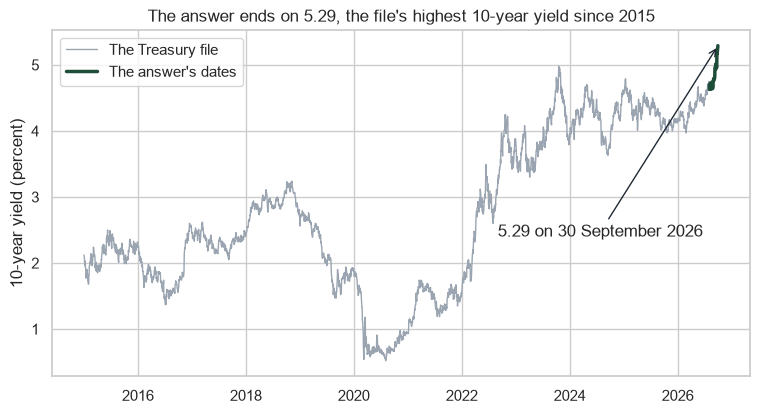

In [5]:
# the 10-year yield over the whole file in grey, the dates the answer covers in dark green
answer_days = treasury.loc['2026-08-03':'2026-09-30', '10 Yr']
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(treasury.index, treasury['10 Yr'], linewidth=1, color='#9AA5B1', label='The Treasury file')
ax.plot(answer_days.index, answer_days, linewidth=2.5, color='#1E4D3A', label="The answer's dates")
ax.annotate('5.29 on 30 September 2026', xy=(answer_days.index[-1], 5.29),
            xytext=(pd.to_datetime('2022-09-01'), 2.4),
            arrowprops={'arrowstyle': '->', 'color': '#1F2933'})
ax.set_title("The answer ends on 5.29, the file's highest 10-year yield since 2015")
ax.set_ylabel('10-year yield (percent)')
ax.legend(loc='upper left')
plt.show()

In FRED's text the value sits in quotes, `"5.29"`: text, not yet a number.
Notebook 02 reads that text as data.

**FRED's answer is text you can read, and its 5.29 on 30 September is the Treasury file's 5.29.**

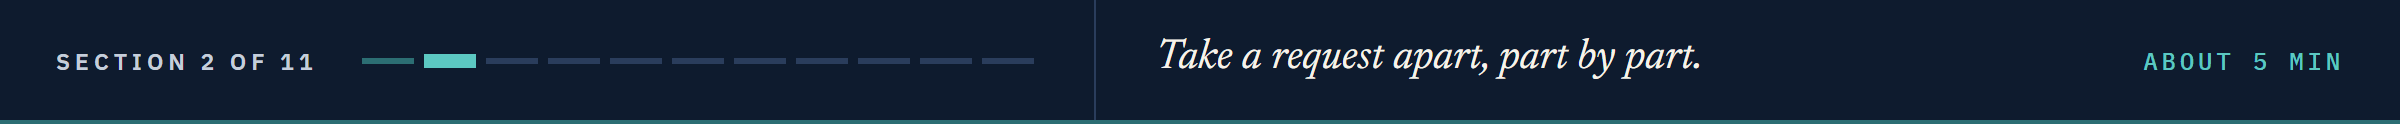

## 1.2 The Request, Taken Apart

How was that answer asked for?

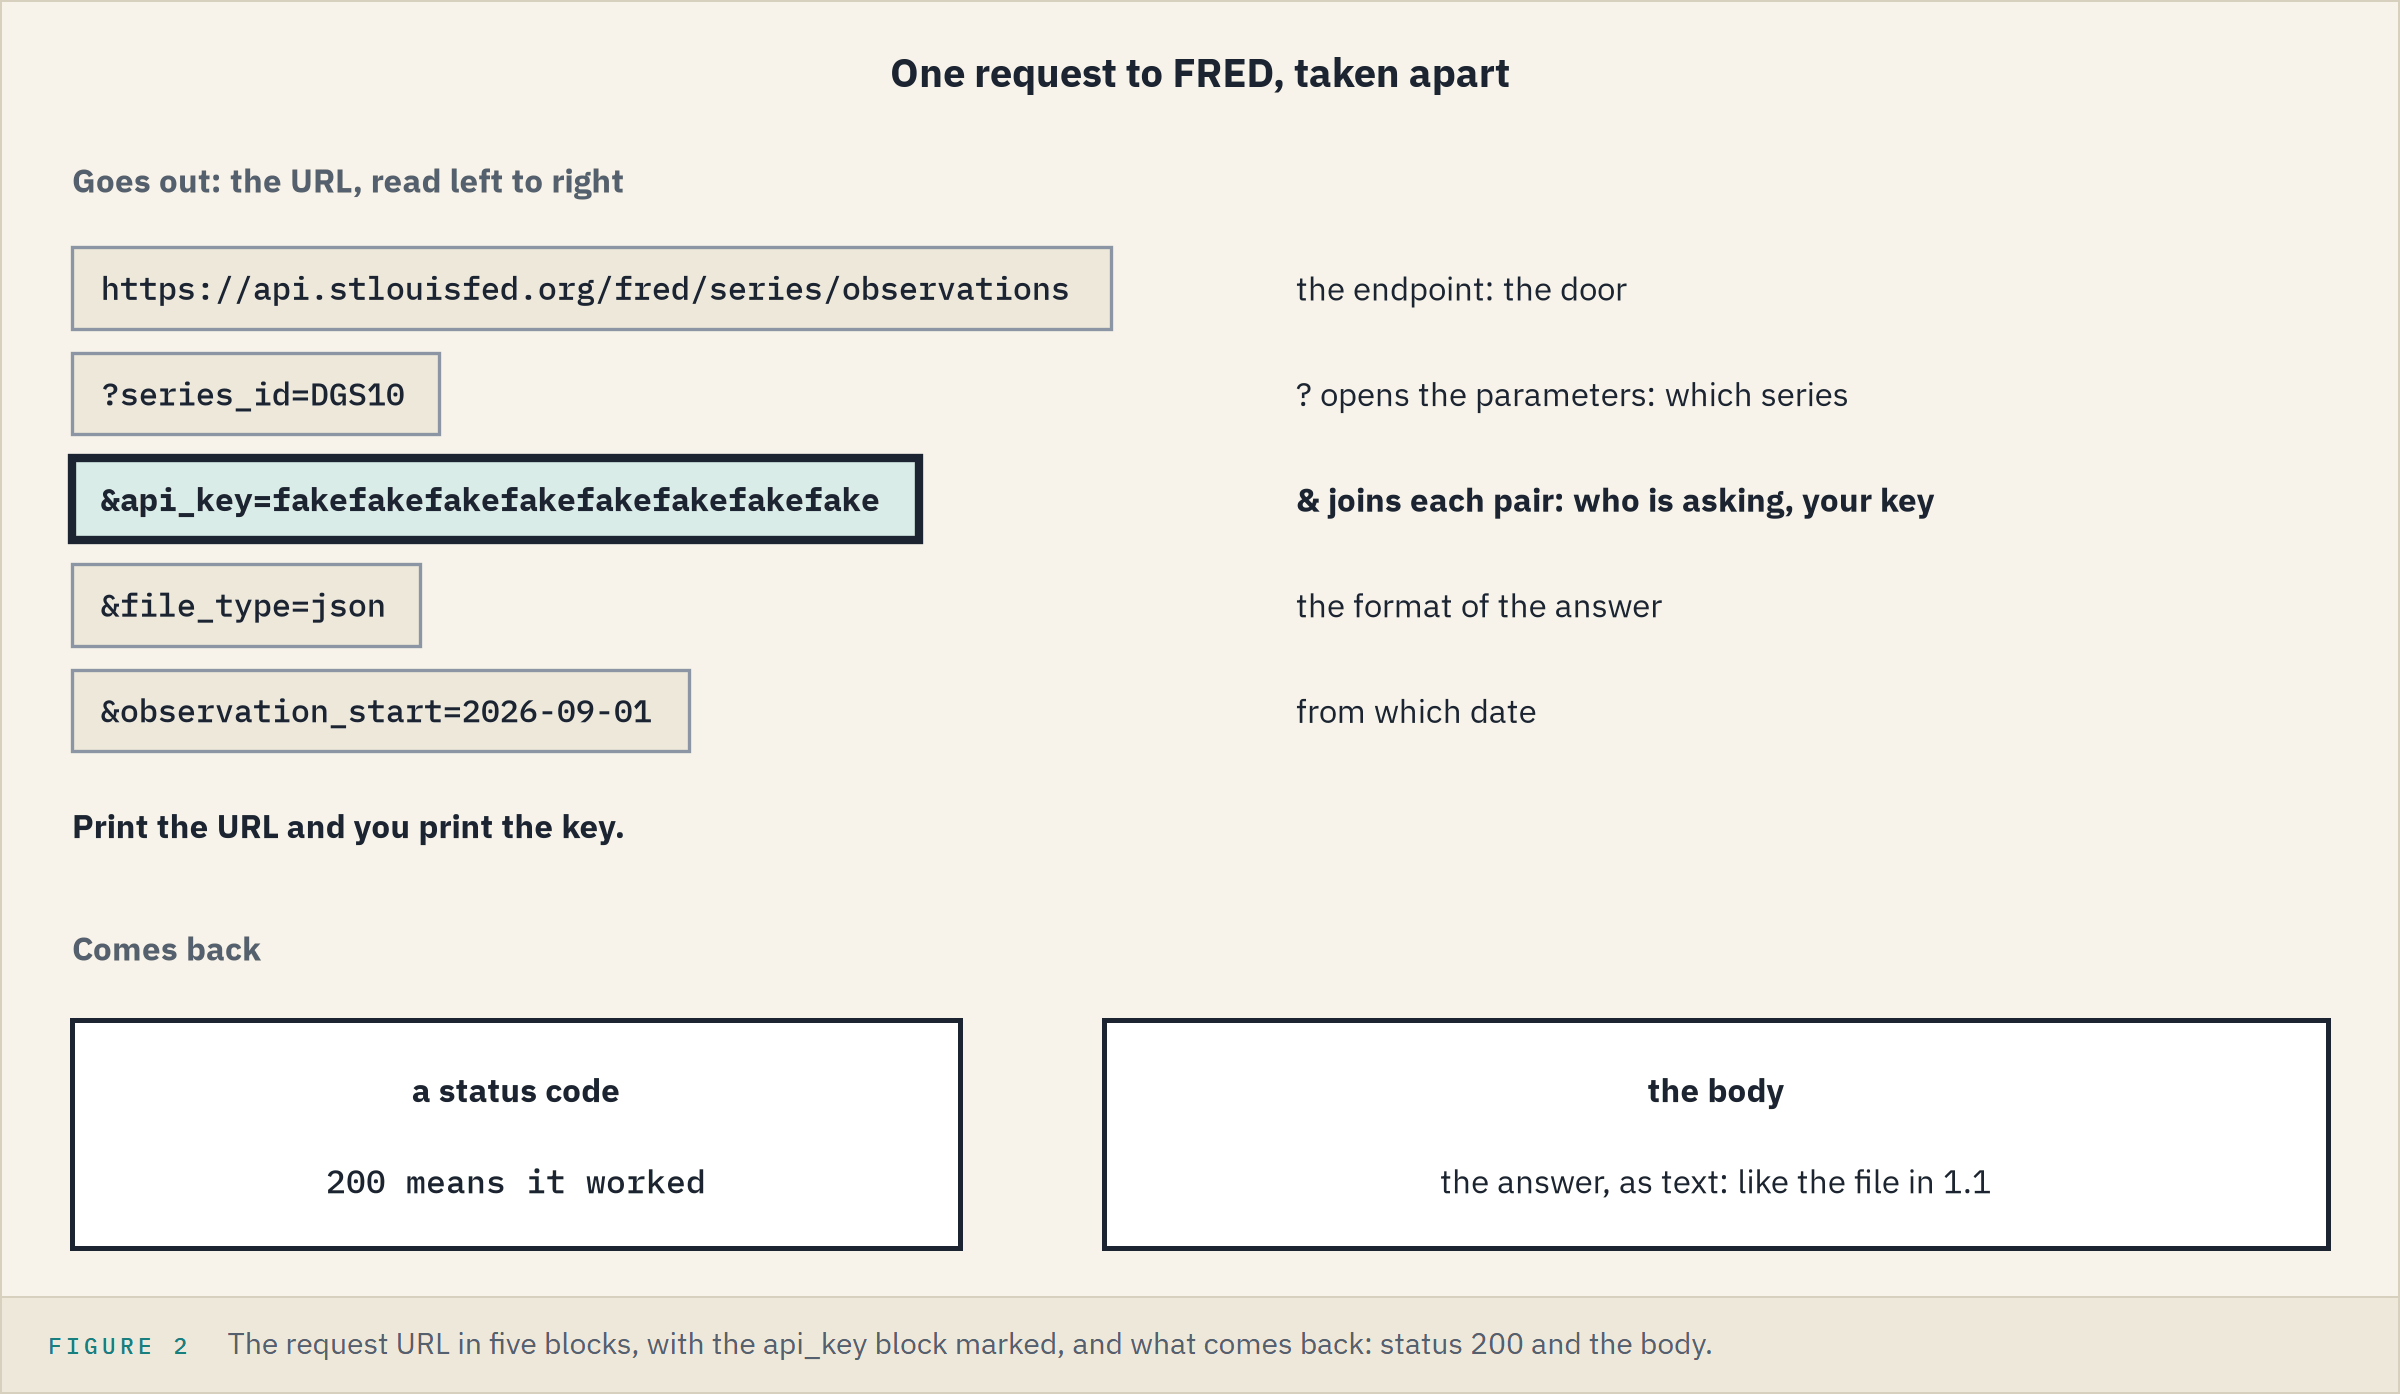

A request to a web API has four parts.
Two go out: the **endpoint**, the URL of the door, and the **query parameters**: `name=value` pairs after a `?`, joined by `&`.
Two come back: a **status code**, a number saying how it went, and the **body**, the answer.

### The Address and the Fake Key

In [6]:
# the course's fake key: 32 lowercase letters, the shape of a FRED key, obviously not one
FAKE_KEY = 'fakefakefakefakefakefakefakefake'
# FRED's door for the observations of one series
FRED_URL = 'https://api.stlouisfed.org/fred/series/observations'
print(len(FAKE_KEY), 'characters')

32 characters


FRED documents a key as "a 32 character lower-cased alpha-numeric string" (https://fred.stlouisfed.org/docs/api/api_key.html, read 2026-10-04).
The fake key has the shape and opens nothing; it goes under `DEMO_API_KEY`, never `FRED_API_KEY`.

### Build the URL

Q. What is the request for the 10-year yield, `DGS10`, from September 2026?

In [7]:
# which series, whose key, which format, from which date
params = {'series_id': 'DGS10', 'api_key': FAKE_KEY, 'file_type': 'json',
          'observation_start': '2026-09-01'}
# name=value for each pair, joined by &, after the address and a ?
request_url = FRED_URL + '?' + '&'.join([f'{name}={value}' for name, value in params.items()])
print(request_url)

https://api.stlouisfed.org/fred/series/observations?series_id=DGS10&api_key=fakefakefakefakefakefakefakefake&file_type=json&observation_start=2026-09-01


The key rides inside the URL: print, log, or quote a URL and the key goes with it.

**Excel side by side.** A1 holds `DGS10`, B1 the fake key, C1 the text `2015-01-01`.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">The URL from its parts</td><td align="left"><code>request_url</code>, starting 2015-01-01</td><td align="left"><code>="https://api.stlouisfed.org/fred/series/observations?series_id="&amp;A1&amp;"&amp;api_key="&amp;B1&amp;"&amp;file_type=json&amp;observation_start="&amp;ENCODEURL(C1)</code></td><td align="left">the full URL, fake key inside</td></tr>
<tr><td align="left">Encode text for a URL</td><td align="left"><code>quote('a b&amp;c=d/e?f', safe='')</code></td><td align="left"><code>=ENCODEURL("a b&amp;c=d/e?f")</code></td><td align="left"><code>a%20b%26c%3Dd%2Fe%3Ff</code></td></tr>
</table>
<br clear="left">

Excel's `&` operator joins text as Python's `+` does; the `&` inside the quotes is the URL's own separator.
`ENCODEURL` leaves an ISO date unchanged.

### Same URL as Excel's

In [8]:
from urllib.parse import quote

# Excel's start date, then Excel's result, typed as two pieces joined by +
url_2015 = request_url.replace('2026-09-01', '2015-01-01')
excel_url = (FRED_URL + '?series_id=DGS10&api_key=fakefakefakefakefakefakefakefake'
             + '&file_type=json&observation_start=2015-01-01')
print('Same URL as Excel:', url_2015 == excel_url)
# safe='' encodes every character that means something in a URL, as ENCODEURL does
print(quote('a b&c=d/e?f', safe=''))

Same URL as Excel: True
a%20b%26c%3Dd%2Fe%3Ff


**Predict 1**

Q. You send that request with a key of the right shape that FRED never issued. What status code comes back? Write down a number.

### What FRED Answered to Five Requests

In [9]:
status_table = pd.DataFrame({
    'Request': ['Everything right', 'A key of the right shape FRED never issued',
                'A key of the wrong shape', 'A series that does not exist',
                'More than 120 requests in a minute'],
    'Status': [200, 400, 400, 400, 429],
    "FRED's message": ['(the observations)', 'The value for variable api_key is not registered.',
                       '... is not a 32 character alpha-numeric lower-case string.',
                       'The series does not exist.', "(FRED's documented limit)"],
})
caption = 'What FRED answered on 2026-10-04, and its documented limit'
status_table.style.hide(axis='index').set_caption(caption)

Request,Status,FRED's message
Everything right,200,(the observations)
A key of the right shape FRED never issued,400,The value for variable api_key is not registered.
A key of the wrong shape,400,... is not a 32 character alpha-numeric lower-case string.
A series that does not exist,400,The series does not exist.
More than 120 requests in a minute,429,(FRED's documented limit)


400, with "The value for variable api_key is not registered."
A code in the 400s means the fix is on your side; 429 is FRED's limit of 120 requests a minute (https://fred.stlouisfed.org/docs/api/fred/errors.html).

**The key rides inside the URL, so anything that prints a URL prints your key; FRED's error messages never repeat it.**

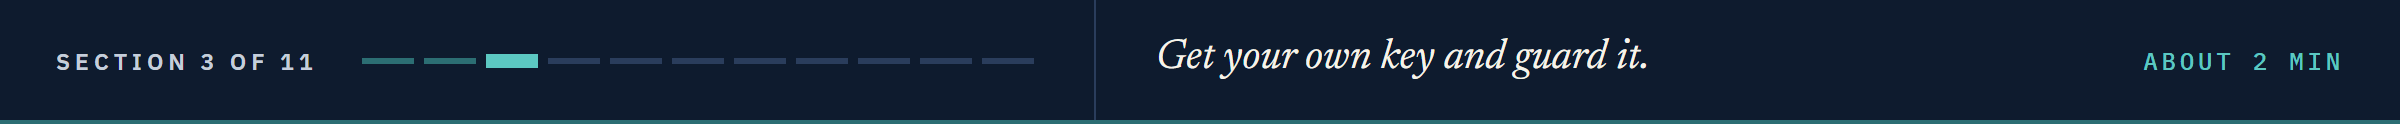

## 1.3 Your Own Key, Kept Like a Password

The note's second ask.

The key is free:

1. Sign in, or create a free account, at https://fredaccount.stlouisfed.org/apikeys: FRED shows and issues keys only to a signed-in account.
2. Request a key on that page.
3. Copy it, and paste it nowhere yet: Bring It Home gives it its place.

FRED's key page (https://fred.stlouisfed.org/docs/api/api_key.html, read 2026-10-04) says so, and sets one key per person: "All users of an application shall use their own API key", and "Developers should request a distinct API key for each application they build."

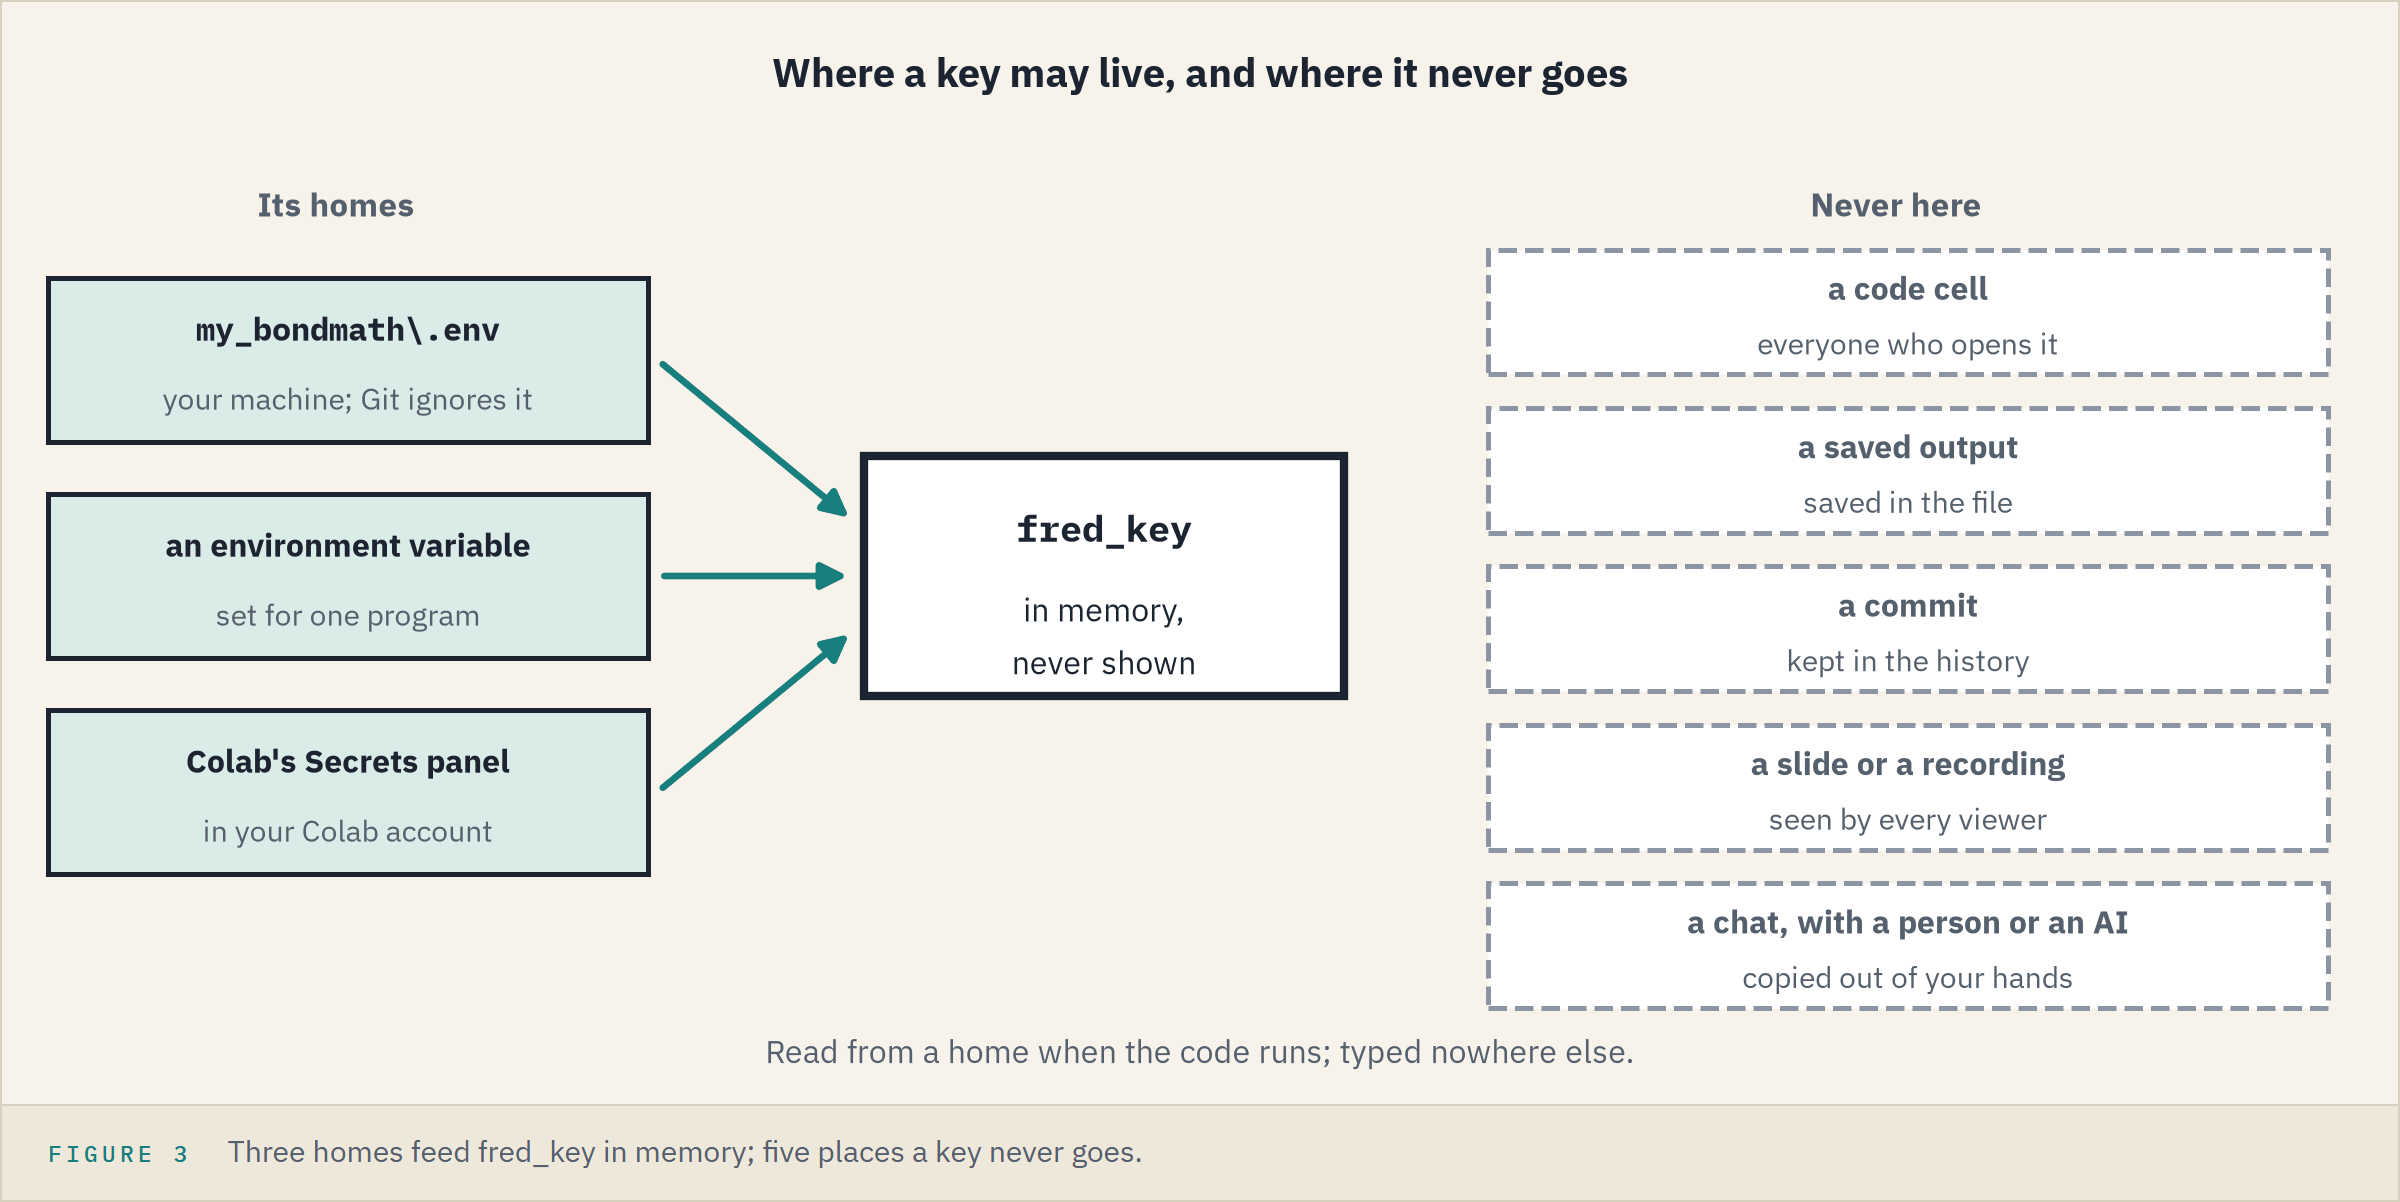

The same page: "All web service requests require an API key to identify requests."
Whoever holds your key is you.
A FRED key opens only public data, so it is the right key to learn on; the habits protect keys that cost money or open client systems.
Your key, not your firm's: at work, firm policy decides; in Colab, use public or synthetic data only.

**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">A key typed into a cell</td><td align="left">never: the code reads it from outside when it runs</td><td align="left">the fake key in B1, column B hidden, saved as <code>.xlsx</code></td><td align="left">still in the file, in <code>xl/sharedStrings.xml</code>, and back in B1 on reopening</td></tr>
</table>
<br clear="left">

Every copy of that workbook carries the key.

**A key is a password that works on every request: yours alone, and never typed where someone else can read it.**

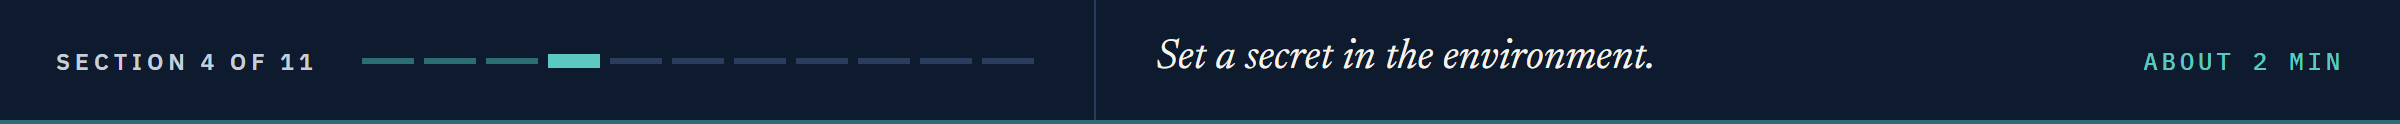

## 1.4 Environment Variables

Every program runs with named text values around it, its **environment variables**.

### Is DEMO_API_KEY There?

In [10]:
# os.environ holds the environment variables, like a dictionary of text
print('DEMO_API_KEY' in os.environ)
# .get gives None, not an error, for a name that is not there
print(os.environ.get('DEMO_API_KEY'))

False
None


### Set It, Compare, Remove It

In [11]:
os.environ['DEMO_API_KEY'] = FAKE_KEY
# compare the value instead of printing it: the habit for every secret, fake or real
print('The value is the fake key:', os.environ['DEMO_API_KEY'] == FAKE_KEY)
del os.environ['DEMO_API_KEY']
print('DEMO_API_KEY' in os.environ)

The value is the fake key: True
False


Set this way, it lives only in this notebook's Python.
PowerShell sets one in two ways, shown here as text:

```powershell
# this terminal window only
$env:DEMO_API_KEY = "..."
# saved for your Windows user
[Environment]::SetEnvironmentVariable("DEMO_API_KEY", "...", "User")
```

Both land in PowerShell's history file, the list the up arrow walks through, so a real key goes in a file typed in an editor.

**A secret in the environment sits outside the code: the code asks for it by name.**

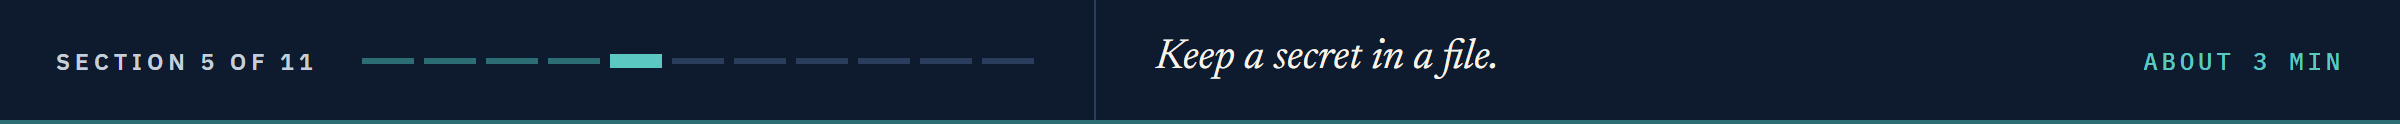

## 1.5 The `.env` File and `.env.example`

A `.env` file holds `NAME=value` lines, one secret to a line: a widely used convention.
Its values never go into Git; `.env.example`, the same names with empty values, does.

### Write the Drill's `.env`

In [12]:
%%writefile .env
# today's drill: the course's fake key, never a real one
DEMO_API_KEY=fakefakefakefakefakefakefakefake

Writing .env


The plainest form every tool reads: no spaces around `=`, no quotes; a `#` line is a comment.

### Write `.env.example`

In [13]:
%%writefile .env.example
# the names of the secrets this folder needs, with no values. Copy it to .env and fill in the values.
DEMO_API_KEY=

Writing .env.example


### Read It

In [14]:
# python-dotenv's dotenv_values reads NAME=value lines into a dictionary
from dotenv import dotenv_values
values = dotenv_values('.env')
print('Names:', list(values))
print('The value is the fake key:', values['DEMO_API_KEY'] == FAKE_KEY)
print('DEMO_API_KEY in os.environ:', 'DEMO_API_KEY' in os.environ)

Names: ['DEMO_API_KEY']
The value is the fake key: True
DEMO_API_KEY in os.environ: False


The environment is untouched.
`load_dotenv` would copy the values into `os.environ`; the course reads the named file and copies nothing.

**Predict 2**

Q. Set `DEMO_API_KEY` in the environment to another value, then read the same `.env` with `dotenv_values`. The dictionary holds:

A) the environment's value
B) the file's value
C) an error: one name, two values

### Both at Once

In [15]:
os.environ['DEMO_API_KEY'] = 'a-value-in-the-environment'
values_again = dotenv_values('.env')
print("The dictionary holds the file's value:", values_again['DEMO_API_KEY'] == FAKE_KEY)
del os.environ['DEMO_API_KEY']

The dictionary holds the file's value: True


B: `dotenv_values` looks only at the file.
Which place wins is `get_secret`'s rule, in 1.7.

**`.env` holds the value, `.env.example` holds the names, and only the names will be committed.**

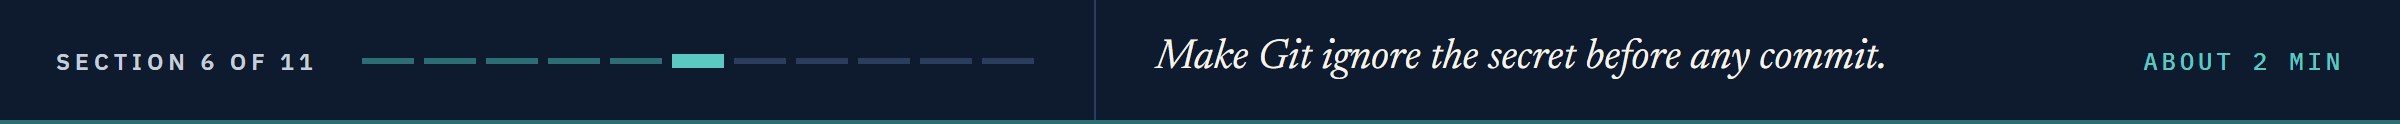

## 1.6 `.gitignore` Before the First Commit

Course 2's notebook 06 used `.gitignore` for Python's folders; here it keeps `.env` out, written before the first commit: 1.10 shows why.
`start_day(1)` made the work folder an empty repository.

### Write `.gitignore`

In [16]:
%%writefile .gitignore
# secrets: your .env holds real keys and is never committed
.env
# downloaded data and databases: rebuilt, never part of the record
cache/
*.db
# folders Python and pytest make
__pycache__/
.pytest_cache/

Writing .gitignore


`cache/` and `*.db` wait for notebook 05's cache and notebook 11's database.

### What Git Sees

In [17]:
!git -C "{work}" status --short --ignored

?? .env.example
?? .gitignore
!! .env
!! bondmath.py
!! course3_excel_reference.csv
!! course3_fred_format_dgs10.json
!! treasury_par_yields.csv


`!!` marks an ignored name, as in Course 2's notebook 11: `.env` by `.gitignore`, the copied data files and `bondmath.py` by the work folder's own ignore list.
`??` marks the files that belong in the record.

### Which Line Keeps `.env` Out?

In [18]:
# check-ignore -v names the file, the line number, and the pattern that matched
!git -C "{work}" check-ignore -v .env

.gitignore:2:.env	.env


**`.env` is ignored before anything is committed, and `check-ignore` names the line that does it.**

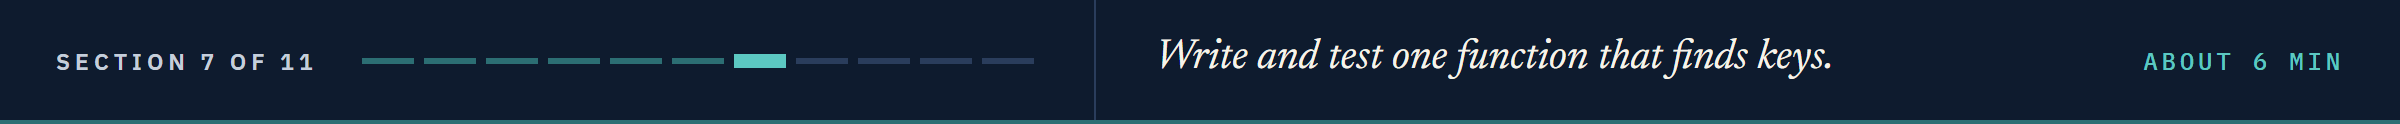

## 1.7 `get_secret`, Docstring First

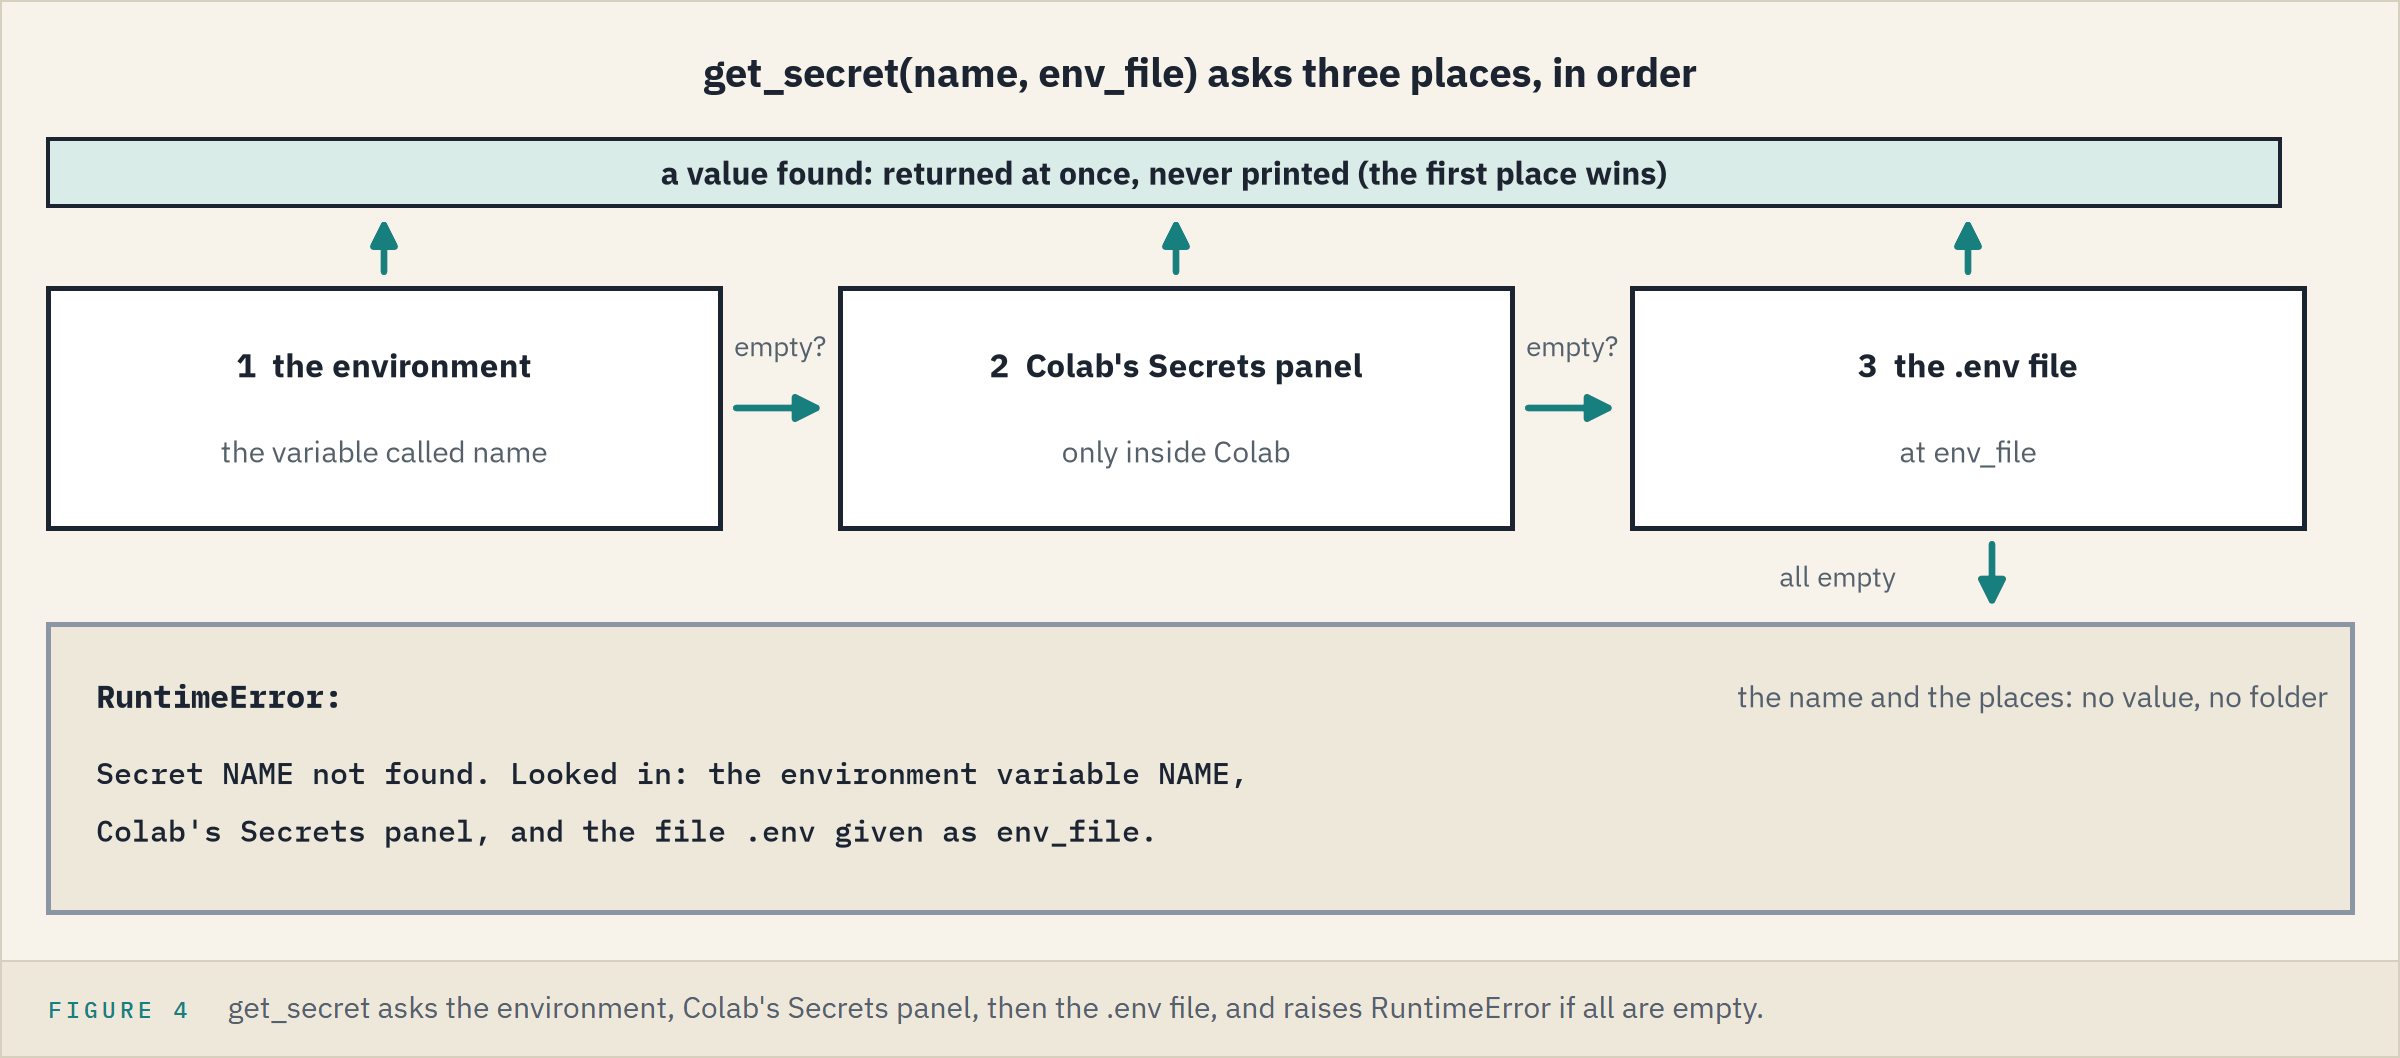

The note's next ask: one function that finds the key.
Like a file in Course 2's notebook 01, a key can be in three places, and `get_secret` asks each in order.

### Start `marketdata.py`

The module docstring holds the conventions every day keeps; its last line is the rule for secrets.

In [19]:
%%writefile marketdata.py
"""marketdata: dated market series for fixed income, checked against Excel.

Written day by day in Python for Fixed Income, Course 3: Market Data and Time Series.

Conventions, the same in every function:
- A series has a DatetimeIndex named date: naive calendar dates (no time, no time zone), unique and ascending.
- Yields are in percent (5.29 means 5.29 percent), as Treasury and FRED publish them. Spreads are in basis points.
- Changes of yields and spreads are in basis points. Price changes are simple returns in percent.
- Windows are counted in observations (rows of the market calendar), trailing, and include the current row.
- A missing observation is NaN. It is dropped before any change or window is computed, never filled.
- A secret (an API key) is never printed, written to a file, or put in an error message.
"""
import os  # environment variables
from pathlib import Path  # file paths

Writing marketdata.py


### Append `get_secret`

Read the docstring before you run the cell.
`ImportError` is the family `ModuleNotFoundError` belongs to, and `except (A, B):` catches either of two errors.
An import inside a function runs only when that line is reached, so Colab never needs `python-dotenv`.
`.is_file()` asks whether a path is a file, and `str | Path` in the first line reads "text or a `Path`".

In [20]:
%%writefile -a marketdata.py


def get_secret(name: str, env_file: str | Path) -> str:
    """Return a secret such as an API key, looked up in three places in a fixed order.

    Units: none; the secret is text. Convention: the first place that holds a non-empty value wins:
    1. the environment variable `name`;
    2. Colab's Secrets panel (google.colab.userdata), only when running in Colab;
    3. the .env file at `env_file`, read with dotenv.dotenv_values, which does not change os.environ.
    The value is returned and never printed. Raises RuntimeError naming the secret and the three places
    looked, never a value and never the full path of the file.
    """
    # 1. the environment: a variable set in PowerShell, or by the program that started Python
    value = os.environ.get(name)
    if value:
        return value

    # 2. Colab's Secrets panel: the import works only inside Colab
    try:
        from google.colab import userdata
    except ImportError:
        userdata = None
    if userdata is not None:
        try:
            value = userdata.get(name)
        # a secret that is not there, or one the notebook has not been given access to
        except (userdata.SecretNotFoundError, userdata.NotebookAccessError):
            value = None
        if value:
            return value

    # 3. the .env file, imported here so Colab never needs python-dotenv
    env_path = Path(env_file)
    if env_path.is_file():
        from dotenv import dotenv_values
        value = dotenv_values(env_path).get(name)
        if value:
            return value

    # nothing found: say where we looked, with the file's name only (a full path shows a user name)
    raise RuntimeError(
        f"Secret {name} not found. Looked in: the environment variable {name}, "
        f"Colab's Secrets panel, and the file {env_path.name} given as env_file."
    )

Appending to marketdata.py


### Find the Drill's Key

In [21]:
import marketdata as md

secret = md.get_secret('DEMO_API_KEY', env_file='.env')
# compare, never print
print(f'Found the fake key: {secret == FAKE_KEY}, {len(secret)} characters')

Found the fake key: True, 32 characters


No variable and no Colab, so the file answered.

### A Secret That Is Nowhere

In [22]:
try:
    md.get_secret('NO_SUCH_SECRET', env_file='.env')
except RuntimeError as error:
    print(error)

Secret NO_SUCH_SECRET not found. Looked in: the environment variable NO_SUCH_SECRET, Colab's Secrets panel, and the file .env given as env_file.


The name and the three places: no value, no folder.

### Four Tests

A pytest **fixture** is a tool a test receives by naming it as an argument.
`monkeypatch` sets or removes an environment variable for one test only; `tmp_path` gives each test its own empty folder; `write_text` writes a whole file.

In [23]:
%%writefile test_marketdata.py
"""Tests for marketdata.py.

Expected values come from Excel (course3_excel_reference.csv in this folder), from the course's data files, or
from small hand examples. No test touches the network or needs a real key: the only key is the course's fake one.
Run from this folder with:  python -m pytest
"""
import pytest

import marketdata as md

# the course's fake key: 32 lowercase letters, the shape FRED expects, obviously not a key
FAKE_KEY = "fakefakefakefakefakefakefakefake"
# the demo name; never FRED_API_KEY, because get_secret checks the environment first
DEMO_NAME = "DEMO_API_KEY"


def test_get_secret_reads_environment(monkeypatch, tmp_path):
    # monkeypatch sets the variable for this test only and removes it afterwards
    monkeypatch.setenv(DEMO_NAME, FAKE_KEY)
    assert md.get_secret(DEMO_NAME, env_file=tmp_path / ".env") == FAKE_KEY


def test_get_secret_reads_env_file(monkeypatch, tmp_path):
    # no variable in the environment, so the file is used
    monkeypatch.delenv(DEMO_NAME, raising=False)
    env_file = tmp_path / ".env"
    env_file.write_text(f"{DEMO_NAME}={FAKE_KEY}\n", encoding="utf-8")
    assert md.get_secret(DEMO_NAME, env_file=env_file) == FAKE_KEY


def test_get_secret_environment_wins(monkeypatch, tmp_path):
    # both places hold a value: the environment comes first
    env_file = tmp_path / ".env"
    env_file.write_text(f"{DEMO_NAME}=value-from-the-file\n", encoding="utf-8")
    monkeypatch.setenv(DEMO_NAME, FAKE_KEY)
    assert md.get_secret(DEMO_NAME, env_file=env_file) == FAKE_KEY


def test_get_secret_missing_raises_without_value(monkeypatch, tmp_path):
    # the file holds a different secret; the one asked for is nowhere
    monkeypatch.delenv(DEMO_NAME, raising=False)
    env_file = tmp_path / ".env"
    env_file.write_text(f"OTHER_API_KEY={FAKE_KEY}\n", encoding="utf-8")
    with pytest.raises(RuntimeError) as caught:
        md.get_secret(DEMO_NAME, env_file=env_file)
    message = str(caught.value)
    # the message names the secret and the places looked, and holds no value and no folder
    assert DEMO_NAME in message and "environment" in message and ".env" in message
    assert FAKE_KEY not in message
    assert str(tmp_path) not in message

Writing test_marketdata.py


### Run pytest

In [24]:
import subprocess
import sys

# python -m pytest -q on the test file, with this notebook's own Python and no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'test_marketdata.py']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

....                                                                     [100%]
4 passed in 0.50s



### Read the Status, Then Commit

In [25]:
!git -C "{work}" status --short --ignored
!git -C "{work}" add .gitignore .env.example marketdata.py test_marketdata.py
subject = 'Notebook 01: get_secret, a .gitignore, and .env.example'
body = 'Course 3 pulls data with a key, so the key gets a home outside the code first.'
!git -C "{work}" commit -q -m "{subject}" -m "{body}"
!git -C "{work}" show --stat --oneline HEAD

?? .env.example
?? .gitignore
?? marketdata.py
?? test_marketdata.py
!! .env
!! __pycache__/
!! bondmath.py
!! course3_excel_reference.csv
!! course3_fred_format_dgs10.json
!! treasury_par_yields.csv
5ca8845 Notebook 01: get_secret, a .gitignore, and .env.example
 .env.example       |  2 ++
 .gitignore         |  8 ++++++++
 marketdata.py      | 58 ++++++++++++++++++++++++++++++++++++++++++++++++++++++
 test_marketdata.py | 50 ++++++++++++++++++++++++++++++++++++++++++++++
 4 files changed, 118 insertions(+)


The four `??` files went in; `.env` stayed `!!`.

**`get_secret` finds a secret in three places and never shows it, `4 passed` proves it, and the first commit holds four files and no `.env`.**

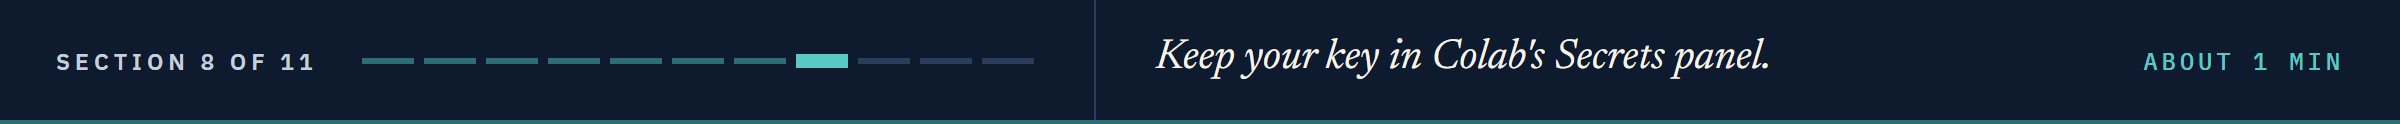

## 1.8 Colab's Secrets Panel

Colab keeps secrets in a panel, not a `.env`:

1. Open **Secrets**, the key icon on the left.
2. Add `FRED_API_KEY` with your key as its value.
3. Turn on **Notebook access**.

The secret stays in your Colab account, so sharing the notebook does not share the key.
Never upload a `.env` to Colab.

**In Colab the key lives in your account's Secrets panel, and `get_secret` asks there second.**

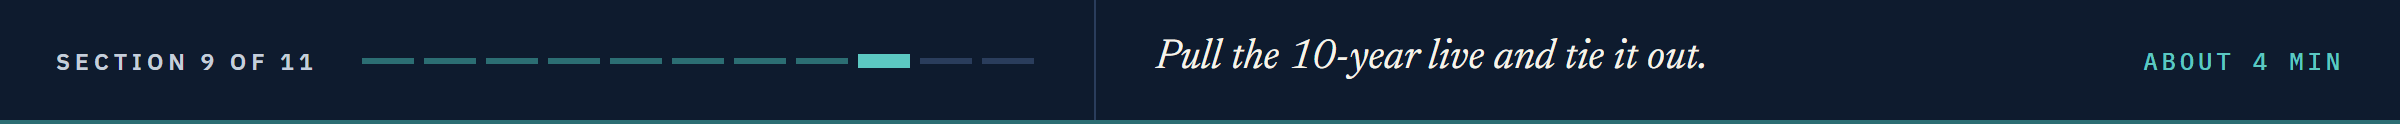

## 1.9 The Key Cell and the First Live Pull

*This product uses the FRED&reg; API but is not endorsed or certified by the Federal Reserve Bank of St. Louis.*

The note's next ask: the 10-year, live.
A **key cell** puts `get_secret`'s answer for `FRED_API_KEY` in `fred_key`, or `None`; each **live cell** checks for `None` first; both are tagged `live-fred`.

**Never type `fred_key` alone in a cell, or `print` it**: Jupyter shows a cell's last value and saves it in the file.

**Never print a URL or a response's `.url`**: the key is inside it.

### Where Your Key Will Live

In [26]:
# your .env file, in my_bondmath, outside every repository; Path.home() is your user folder
ENV_FILE = Path.home() / "projects" / "my_bondmath" / ".env"
# what every live cell prints when no key was found
NO_KEY_MESSAGE = "Live cell skipped: no FRED key was found. Every other cell runs without one."

### The Key Cell

In [27]:
try:
    fred_key = md.get_secret("FRED_API_KEY", env_file=ENV_FILE)
    print("FRED key: found. It is held in memory and is never printed.")
except RuntimeError as error:
    fred_key = None
    print(f"FRED key: not found. Live cells will be skipped. {error}")

FRED key: not found. Live cells will be skipped. Secret FRED_API_KEY not found. Looked in: the environment variable FRED_API_KEY, Colab's Secrets panel, and the file .env given as env_file.


### Pull DGS10 Live

In [28]:
# a live cell: it needs your key and the network
if fred_key is None:
    print(NO_KEY_MESSAGE)
else:
    # one GET request: the address, the parameters (your key among them), a time limit in seconds
    live_params = {'series_id': 'DGS10', 'api_key': fred_key, 'file_type': 'json',
                   'observation_start': '2026-09-01'}
    try:
        live_response = requests.get(FRED_URL, params=live_params, timeout=30)
    except requests.RequestException as live_error:
        # its message holds the URL and your key: name only its class; from None hides the original
        raise RuntimeError(f'The request failed: {type(live_error).__name__}') from None
    # the status code, never the URL: the URL holds your key
    print(f'HTTP status: {live_response.status_code}')
    assert live_response.status_code == 200, live_response.json().get('error_message')
    # .json() reads the body into dictionaries and lists, notebook 02's subject
    # '.' marks a weekday with no value: drop those rows, then read the values as numbers
    live_obs = pd.DataFrame(live_response.json()['observations'])
    live_obs = live_obs[live_obs['value'] != '.'].astype({'value': float})
    # to_string(index=False): the rows as plain text, without the row numbers
    print(live_obs[['date', 'value']].tail(10).to_string(index=False))
    # the check: dates as dates, joined to the snapshot on the date; every shared date must agree
    live_obs['date'] = pd.to_datetime(live_obs['date'])
    live_common = live_obs.merge(treasury.reset_index()[['date', '10 Yr']], on='date')
    live_gap = (live_common['value'] - live_common['10 Yr']).abs().max()
    assert len(live_common) > 0 and live_gap <= 1e-9, 'FRED and the snapshot disagree'
    print(f'{len(live_common)} dates in both, largest gap {live_gap:.1e} percent')

Live cell skipped: no FRED key was found. Every other cell runs without one.


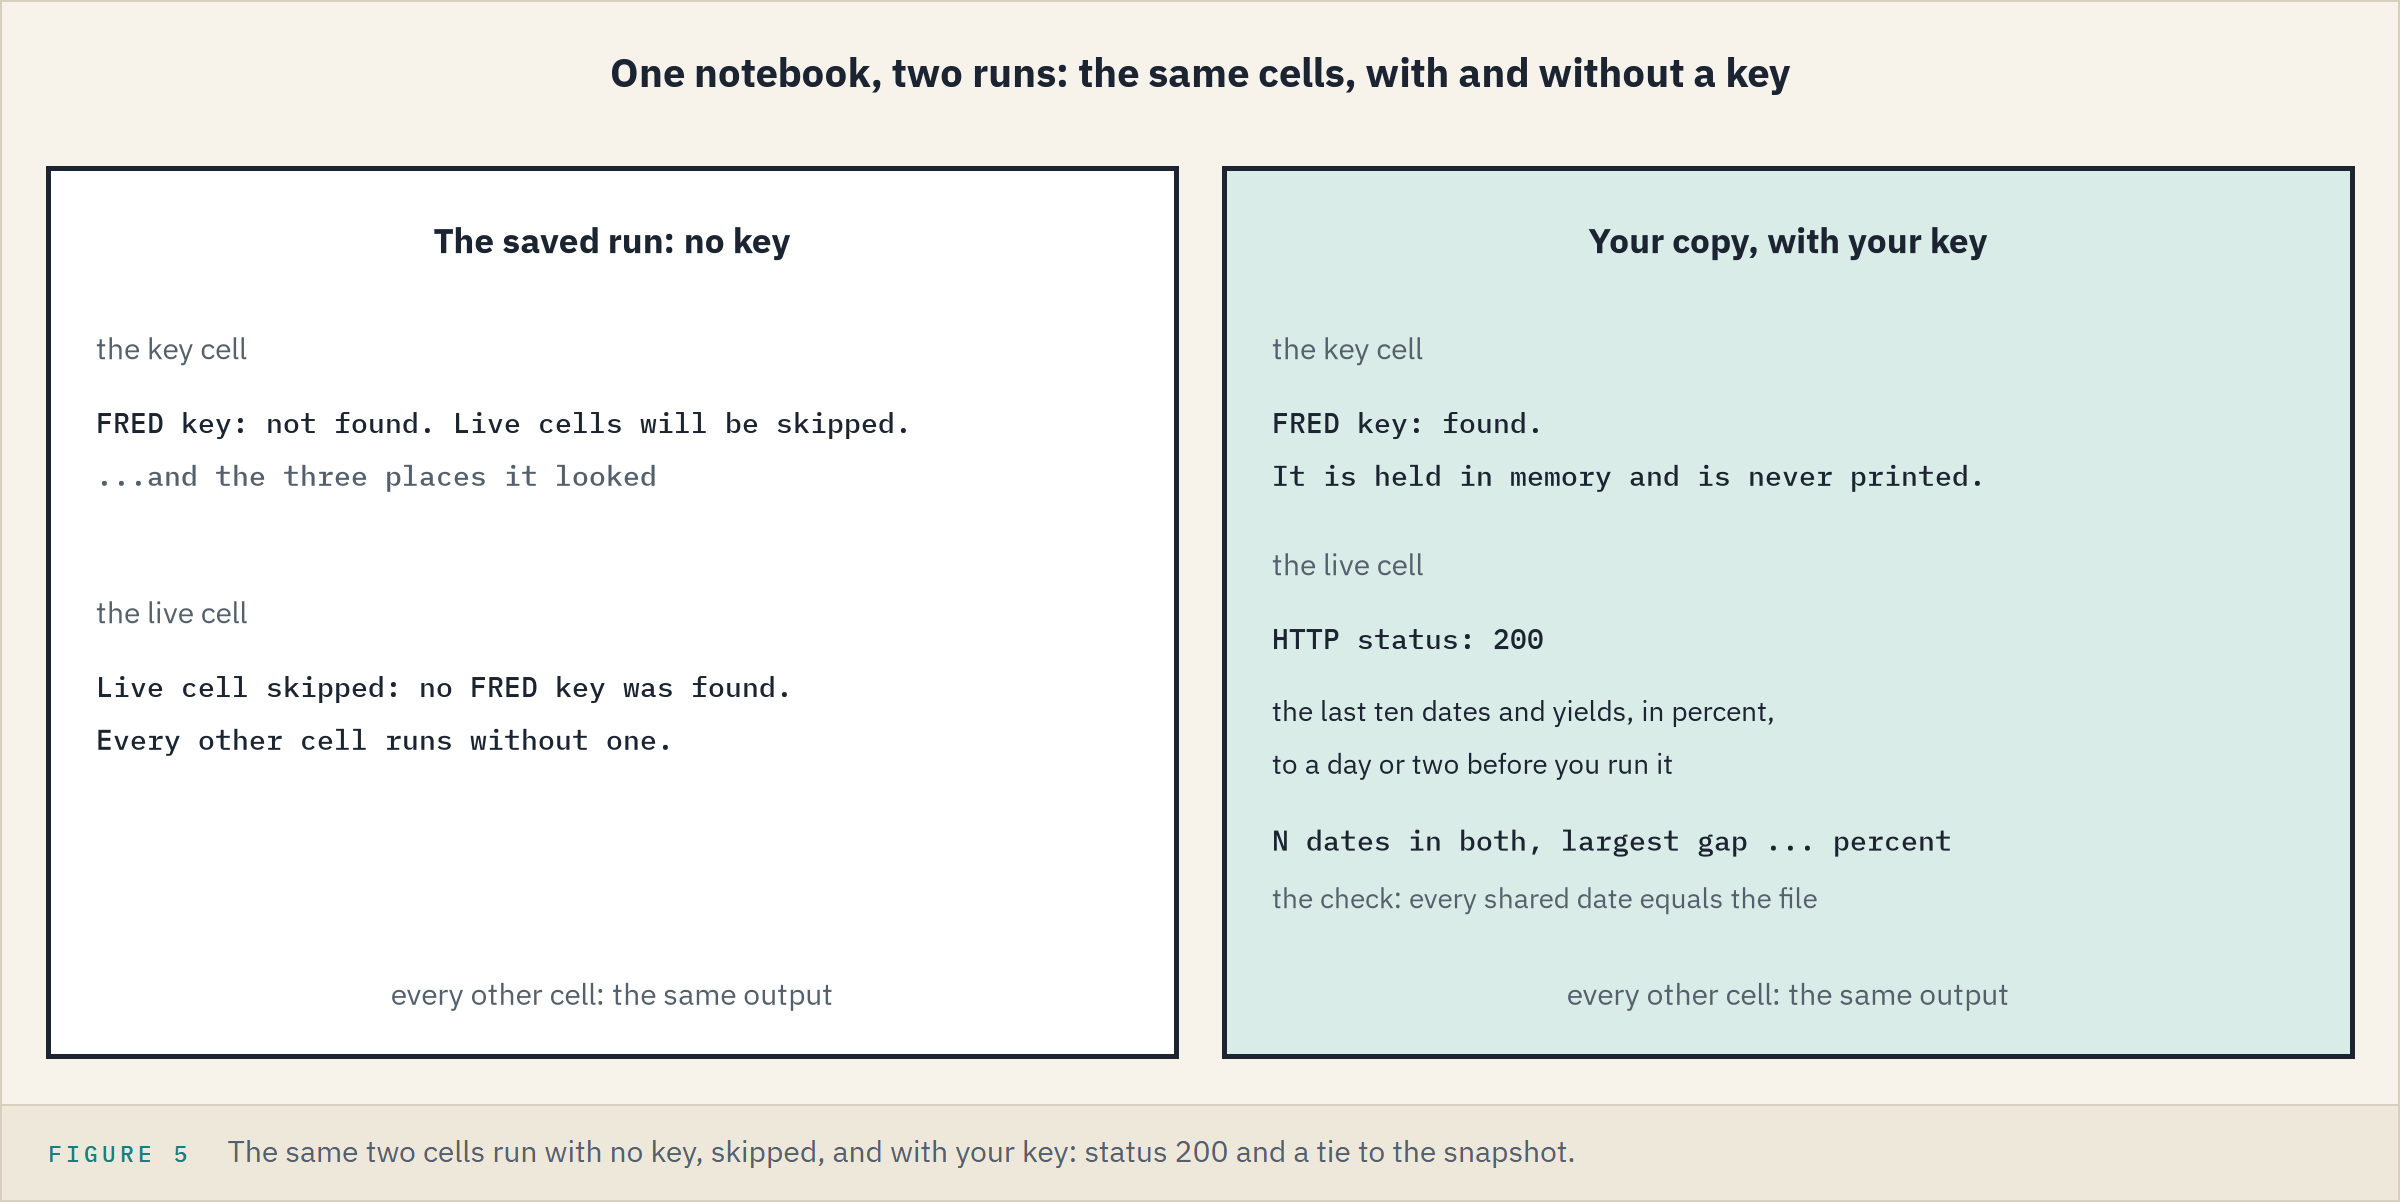

`.astype({'value': float})` turns the named column into numbers.
FRED's `DGS10` is Treasury's series, so every date it shares with the snapshot agrees; later dates are not checked.

**Excel side by side.** Power Query (Data, Get Data, From Other Sources, From Web) loads FRED's website download, which needs no key.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Public data from the web</td><td align="left"><code>requests.get</code> with your key: the API</td><td align="left">From Web on <code>https://fred.stlouisfed.org/graph/fredgraph.csv?id=DGS10</code></td><td align="left">header <code>observation_date</code>, <code>DGS10</code>; 16,913 rows, 1962-01-02 to 2026-10-29, on the day tested</td></tr>
<tr><td align="left"><code>WEBSERVICE</code> on that address</td><td align="left">not used</td><td align="left"><code>=WEBSERVICE("https://fred.stlouisfed.org/graph/fredgraph.csv?id=DGS10")</code></td><td align="left"><code>#VALUE!</code> when tested</td></tr>
</table>
<br clear="left">

**The key cell and the live cell run for everyone: with no key they say so, with yours they pull FRED and tie it to the snapshot.**

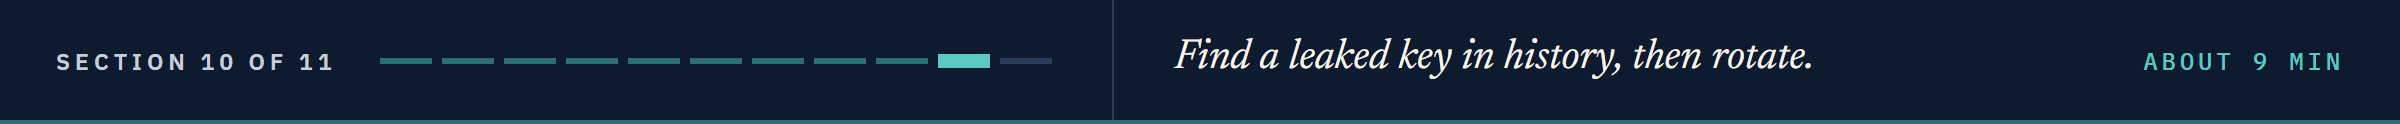

## 1.10 When a Key Leaks

The note's last ask.
A key leaks when it lands where others can read it: a commit, a pushed repository, a saved output, a screenshot, a recording, a chat.

### The Mistake, on Purpose

In [29]:
%%writefile settings.py
# a settings file with a key typed into it: the mistake the drill makes on purpose
DEMO_API_KEY = "fakefakefakefakefakefakefakefake"

Writing settings.py


In [30]:
!git -C "{work}" add settings.py
!git -C "{work}" commit -q -m "Add settings"
!git -C "{work}" log --oneline

db1938d Add settings
5ca8845 Notebook 01: get_secret, a .gitignore, and .env.example


### Ignore It, Then Change It

Someone notices, lists the name in `.gitignore`, and edits the file.

In [31]:
%%writefile -a .gitignore
settings.py

Appending to .gitignore


In [32]:
%%writefile -a settings.py
# one more line

Appending to settings.py


**Predict 3**

Q. `settings.py` is committed and now listed in `.gitignore`. Does `git status` report the new line?

A) No: Git looks away from an ignored name
B) Yes: Git still watches the file
C) Git refuses the edit

### Ask Git

In [33]:
!git -C "{work}" status --short settings.py
# put the file back as committed
!git -C "{work}" restore settings.py

 M settings.py


B: ` M settings.py`.
`.gitignore` only stops Git from starting to track a file; it does not untrack one already in a commit.

### Delete It the Git Way

In [34]:
# git rm deletes the file and stages the delete; -q keeps it quiet
!git -C "{work}" rm -q settings.py
!git -C "{work}" add .gitignore
!git -C "{work}" commit -q -m "Remove settings.py and ignore it"
# ls-files lists every file Git tracks
!git -C "{work}" ls-files

.env.example
.gitignore
marketdata.py
test_marketdata.py


### Search the History

In [35]:
# Course 2's pickaxe, on the fake key, limited to settings.py
!git -C "{work}" log --oneline -S {FAKE_KEY} -- settings.py

11224b4 Remove settings.py and ignore it
db1938d Add settings


Two commits: the one that added the key and the one that removed it.

**Predict 4**

Q. Search again with no file named. How many commits does Git list? Write down a number.

### Every File

In [36]:
!git -C "{work}" log --oneline -S {FAKE_KEY}

11224b4 Remove settings.py and ignore it
db1938d Add settings
5ca8845 Notebook 01: get_secret, a .gitignore, and .env.example


Three: the first commit too, where `test_marketdata.py` holds the fake key on purpose.
When a real key leaks, search with no file named.

### Read It Back

In [37]:
# <commit>:<file> shows a file as it was in that commit; HEAD~1 is the one before the last
!git -C "{work}" show HEAD~1:settings.py

# a settings file with a key typed into it: the mistake the drill makes on purpose
DEMO_API_KEY = "fakefakefakefakefakefakefakefake"


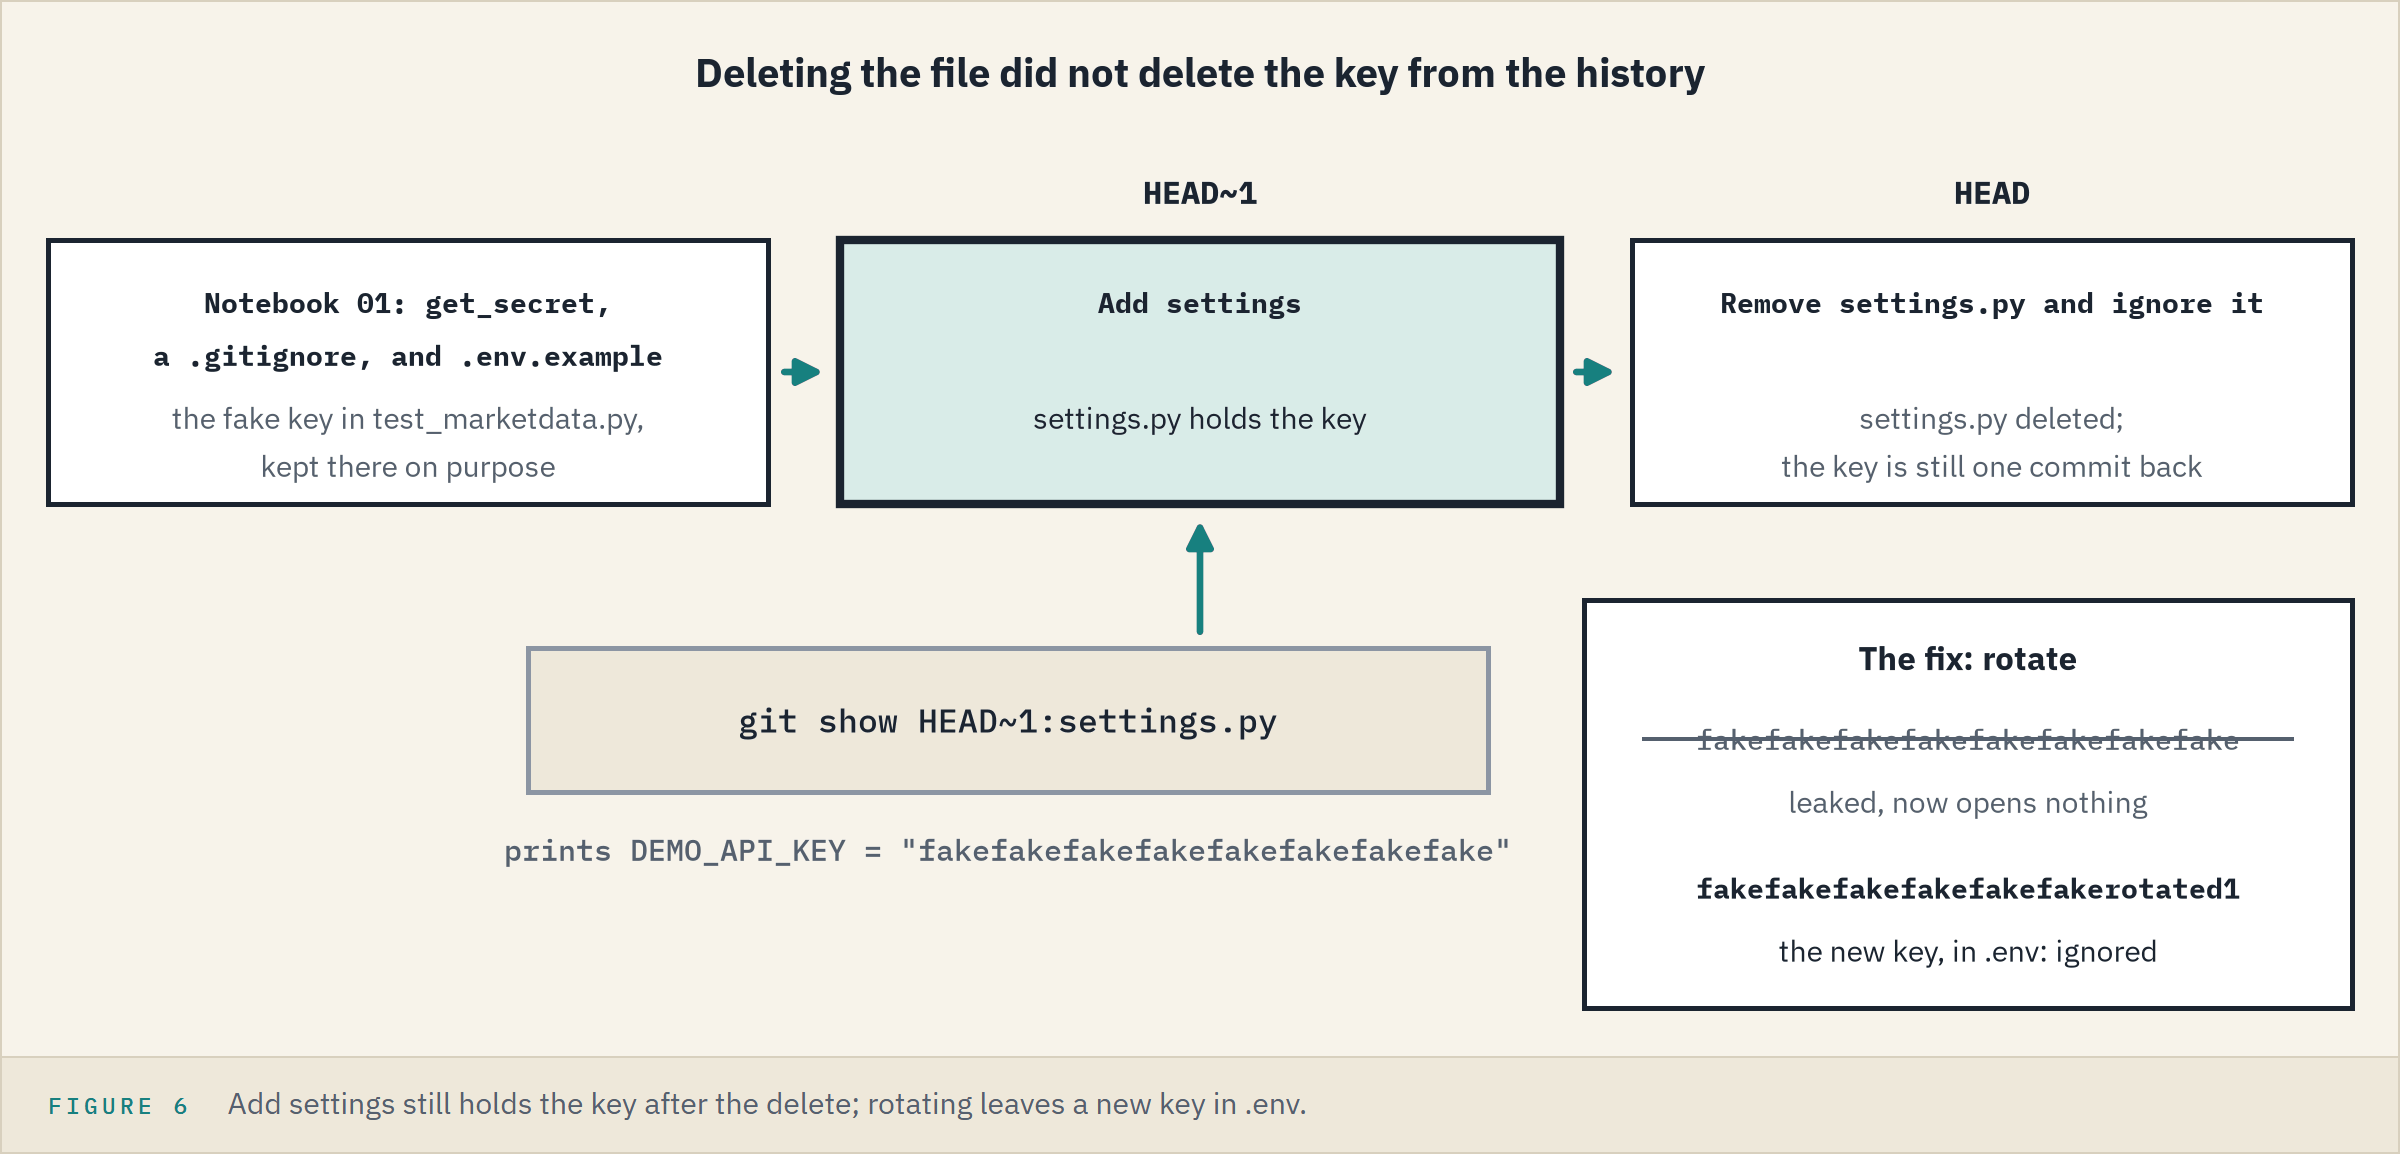

The key, read straight out of the history after the delete, as anyone with a copy can.
A workbook is no different, as in 1.3: every copy saved before the key left its cell still holds it.

### Rotate

Rotate first: on FRED's key page request a new key, put it in `.env`, and remove the old key there if the page offers it.

In [38]:
%%writefile .env
# today's drill, after rotating: a new fake key replaces the leaked one
DEMO_API_KEY=fakefakefakefakefakefakerotated1

Overwriting .env


In [39]:
!git -C "{work}" status --short --ignored .env
ROTATED_FAKE_KEY = 'fakefakefakefakefakefakerotated1'
rotated = md.get_secret('DEMO_API_KEY', env_file='.env')
print('get_secret returns the new key:', rotated == ROTATED_FAKE_KEY)

!! .env
get_secret returns the new key: True


`!! .env`: ignored, so rotating leaves nothing to commit; the leaked key still sits in `Add settings`, opening nothing.
Rewriting history to take a file out of every commit exists, but it is slow, changes every later commit, and never reaches copies already made: named here, not done.

> STORY: GitHub, which scans repositories for leaked keys, gives the same order: its documentation says to "rotate the affected credential immediately", and adds: "While you can also remove secrets from your Git history, this is time-intensive and often unnecessary if you've already revoked the credential." Sources: GitHub Docs, "About secret scanning", https://docs.github.com/en/code-security/secret-scanning/introduction/about-secret-scanning, and "Removing sensitive data from a repository", https://docs.github.com/en/authentication/keeping-your-account-and-data-secure/removing-sensitive-data-from-a-repository (both read 2026-10-04).

**Deleting a committed key leaves it in the history; rotating first, the old key removed, makes every copy worthless.**

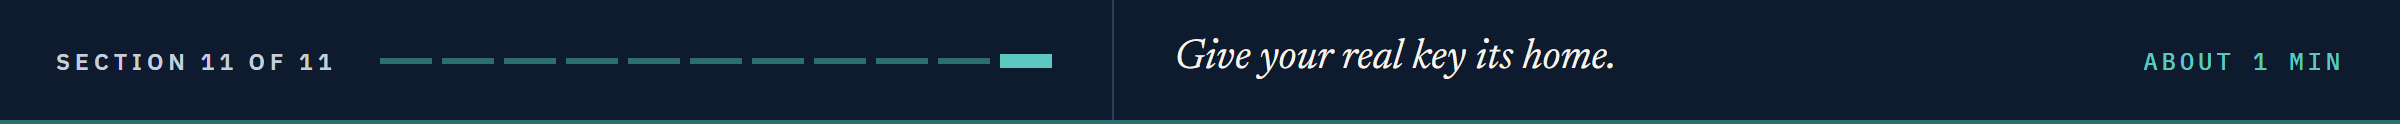

## Bring It Home

Give your real key its home, and bring `marketdata.py` into `my_bondmath`, replacing any there.
The work folder's `.gitignore` and `.env.example` are the drill's: leave them.
In a PowerShell terminal in VS Code, with the course's `.venv` active:

```powershell
# the course's packages, if not yet installed
Set-Location "$HOME\projects\python-fixed-income"
python -m pip install -r course03_market_data\requirements.txt
# ignore .env before it exists
Set-Location "$HOME\projects\my_bondmath"
Add-Content .gitignore ".env", "cache/", "*.db"
Set-Content .env.example "FRED_API_KEY="
code .env
```

In the editor type `FRED_API_KEY=`, paste your key after the `=`, and save: it never touches PowerShell's history.

```powershell
# both must show .env as ignored: if not, stop and fix .gitignore
git check-ignore -v .env
git status --short --ignored
# the work folder: use the name your setup cell printed
$work = "$env:TEMP\pfi_course3_01_k4w7q2xr"
Copy-Item "$work\marketdata.py", "$work\test_marketdata.py" .
python -m pytest -q test_marketdata.py
git add .gitignore .env.example marketdata.py test_marketdata.py
git commit -m "Notebook 01: get_secret, a .gitignore, and .env.example"
```

pytest shows `4 passed`; `.env` is never in the `git add` line.
Restart this notebook and run all cells: the key cell says `found`, and the live cell pulls FRED.
In Colab, download the two files from the work folder under `/tmp`; the key stays in the Secrets panel.

## You Can Now

By the end of this notebook, you can:

* Take a request apart: endpoint, parameters, status code, body.
* Get your own FRED key, and keep it like a password.
* Keep a secret in the environment or a `.env` file, and compare it instead of printing it.
* Put `.gitignore` in place before the first commit, and prove it with `git check-ignore -v`.
* Find a secret in three places with `get_secret`, tested with `monkeypatch` and `tmp_path`.
* Find a deleted key in Git's history, and rotate it.

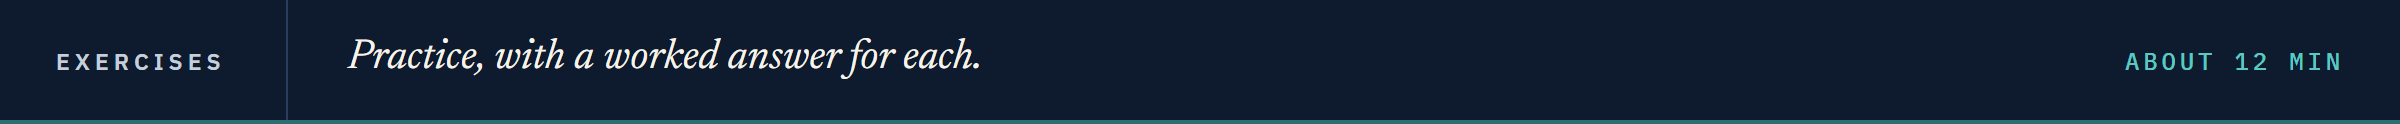

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

Replace each `...` with your own code, then run the check cell under it.
Run the next two cells first: `check`, and a drill file with two secrets.

In [40]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [41]:
%%writefile two_secrets.env
# two demo secrets, both fake
DEMO_API_KEY=fakefakefakefakefakefakefakefake
DEMO_DATA_TOKEN=second-demo-value

Writing two_secrets.env


### Exercise 1

Q. With `md.get_secret`, read `DEMO_DATA_TOKEN` from `two_secrets.env`. Store the value in **ex1_value**.

In [42]:
ex1_value = ...

In [43]:
check('Exercise 1 the second secret', ex1_value, 'second-demo-value')

Exercise 1 the second secret: not attempted yet


### Exercise 2

Q. Set `DEMO_API_KEY` in the environment to `'value-from-the-environment'`; `two_secrets.env` holds the fake key under that name. Predict in a comment what `md.get_secret('DEMO_API_KEY', env_file='two_secrets.env')` returns, then call it, store the result in **ex2_value**, and `del` the variable.

In [44]:
# your prediction:
ex2_value = ...

In [45]:
check('Exercise 2 the environment against the file', ex2_value, 'value-from-the-environment')

Exercise 2 the environment against the file: not attempted yet


### Exercise 3

Q. Add `env_example_text(names)`, docstring first: the text of a `.env.example`, one `NAME=` line per name, each ending in a newline, and `ValueError` for an empty name or one with a space or `=`. Add `test_env_example_text_has_names_and_no_values` for `['FRED_API_KEY', DEMO_NAME]`. Run pytest, reload, and store `md.env_example_text(['FRED_API_KEY', 'DEMO_API_KEY'])` in **ex3_text**.

In [46]:
%%writefile -a marketdata.py


# Exercise 3: write env_example_text(names) below this line

Appending to marketdata.py


In [47]:
%%writefile -a test_marketdata.py


# Exercise 3: write test_env_example_text_has_names_and_no_values() below this line

Appending to test_marketdata.py


In [48]:
# run pytest as in the lesson, reload the module, then call your function
ex3_text = ...

In [49]:
check('Exercise 3 the .env.example text', ex3_text, 'FRED_API_KEY=\nDEMO_API_KEY=\n')

Exercise 3 the .env.example text: not attempted yet


### Exercise 4: AI check

You gave an assistant the docstring below as the prompt; the function came back, written for this course in the style of an assistant's answer, and holds one bug.

Q. Read its last two lines: will the line it returns hold the key? Then run the test under it.

In [50]:
# written for this course in the style of an AI assistant's answer. It contains one bug.
def describe_request(series_id, api_key):
    """Return one line describing a FRED request, safe to print and to write to a log file.

    Units: none; text out. Convention: the line names the endpoint and the series, and never
    holds the API key. A log line is read by people and kept in files, so the key is shown as ***.
    """
    params = {'series_id': series_id, 'api_key': api_key, 'file_type': 'json'}
    # name=value pairs joined by &, the way the request itself is sent
    query = '&'.join([f'{name}={value}' for name, value in params.items()])
    return f'GET {FRED_URL}?{query}'

In [51]:
# the test, written from the docstring before the code is trusted
line = describe_request('DGS10', FAKE_KEY)
assert 'DGS10' in line, 'the line does not name the series'
assert FAKE_KEY not in line, 'the log line holds the API key'
print('The line names the series and holds no key')

AssertionError: the log line holds the API key

Q. Fix the function, then run it and the test again until the test passes. Store `FAKE_KEY not in describe_request('DGS10', FAKE_KEY)` in **ex4_hides_key** and `'DGS10' in describe_request('DGS10', FAKE_KEY)` in **ex4_names_series**.

In [52]:
ex4_hides_key = ...
ex4_names_series = ...

In [53]:
check('Exercise 4 the line hides the key', ex4_hides_key, True)
check('Exercise 4 the line names the series', ex4_names_series, True)

Exercise 4 the line hides the key: not attempted yet
Exercise 4 the line names the series: not attempted yet


## Congratulations!

The note is answered:

<table align="left">
<tr><th align="left">The note asked</th><th align="left">Answer</th></tr>
<tr><td align="left">What FRED sends back</td><td align="left">Text: 43 observations, 5.29 on 2026-09-30, the snapshot's value</td></tr>
<tr><td align="left">Your own key</td><td align="left">Yours alone, in <code>my_bondmath\.env</code> or Colab's Secrets panel</td></tr>
<tr><td align="left">A home outside files and commits</td><td align="left"><code>.env</code> ignored before the first commit</td></tr>
<tr><td align="left">The function, tested</td><td align="left"><code>get_secret</code>, 4 passed</td></tr>
<tr><td align="left">The 10-year live</td><td align="left">Tied to the snapshot on every shared date</td></tr>
<tr><td align="left">A leak, and the fix</td><td align="left">Still in the history after the delete; rotate first</td></tr>
</table>
<br clear="left">

Be proud: every key you handle from here gets these habits.

Next: JSON and the FRED API (notebook 02) turns the text from 1.1 into a dated series, and one live cell into three tested functions.

[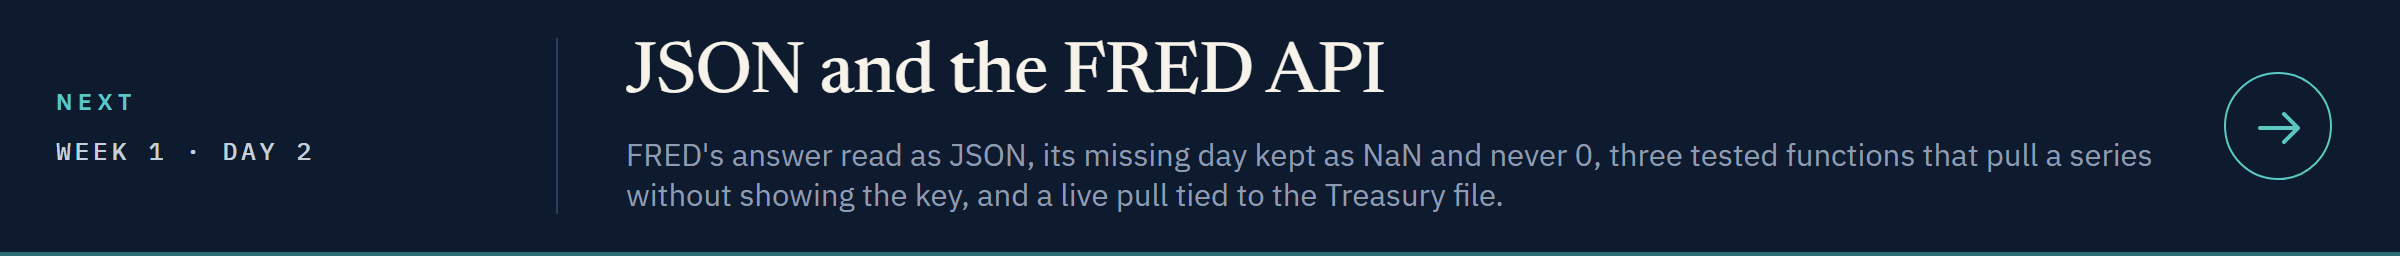](../day2/02_json_and_the_fred_api.ipynb)

[Open Day 2 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course03_market_data/week1/day2/02_json_and_the_fred_api.ipynb)